---
title: "Zwietering's micromixing bounds: what a residence-time distribution cannot tell you"
description: "Complete segregation and maximum mixedness bracket the conversion for a given RTD. The bracket is reproduced against every number Zwietering printed, and it is wide: a factor of 2.1 at kc0*tau = 50."
categories: [sec:A, struct:S1, struct:S3, struct:S5, tier:T0, data:tier6, phase:liquid]
date: 2026-08-05
---

# Zwietering's micromixing bounds: what a residence-time distribution cannot tell you

**Catalog ID:** `A2.8` · **Structures:** `S1` (batch element), `S3` (1-D steady
BVP), `S5` (convection-dominated, TVD) · **Tier:** T0

Four gallery pages treat the residence-time distribution as the answer.
[`A2.1`](../A2.1-danckwerts-boundary-conditions/) asks what boundary conditions
the axial-dispersion model needs, [`A2.3`](../A2.3-taylor-aris-dispersion/)
derives a dispersion coefficient from first principles,
[`A2.5`](../A2.5-edwards-richardson-dispersion/) measures one and
[`A2.6`](../A2.6-gunn-dispersion-correlations/) correlates it. All four end with
an RTD.

This page is about what you still do not know once you have it. Zwietering's
answer is a **pair of bounds**: for a given RTD and a reaction of order other
than one, the achievable exit concentration lies between the completely
segregated value and the maximum-mixedness value, and nothing about the RTD
narrows it further. The useful question is not whether the bounds are correct
(they are) but **how far apart they are**, because that gap is exactly the part
of a reactor's performance that an RTD measurement cannot reach.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A2.8-zwietering-segregation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import time
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import quad, solve_ivp
from scipy.special import exp1, expi
from pymrm import vanleer
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (E_rtd, W_rtd, gamma_seg, gamma_real_seg, gamma_real_mixed,  # this page's model.py
                   gamma_far, MaxMixedness, gamma_mm, mm_ode, var_alpha, J_real_mixed,
                   J_real_seg, J_mm, var_within_mm)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
claims = Claims(PAGE.split("-")[0])

## Background

Danckwerts (1953, the paper behind [`A2.1`](../A2.1-danckwerts-boundary-conditions/))
introduced the *degree of segregation* $J$ and showed that two reactors with
**identical** residence-time distributions can give different conversions, because
the RTD says when molecules leave but not who they were mixed with on the way.
For a first-order reaction that does not matter: the rate is linear, so the
average of the rate is the rate of the average. For any other order it matters a
great deal.

Zwietering's contribution is to close the problem. Danckwerts had one extreme:
**complete segregation**, in which a fluid element entering the vessel keeps its
identity until the exit, so the reactor is a batch reactor whose contents are
mixed only in the outlet pipe. That is mixing *as late as possible*. Zwietering
constructs the opposite extreme, mixing *as early as possible* compatible with
the same RTD, and calls it **maximum mixedness**. Between them, every physically
realisable reactor with that RTD must lie.

The two constructions are the same pipe run in opposite directions
(his Figs. 2 and 3):

- **Complete segregation**: a plug-flow tube with many *side exits*, tapped so
  that the total residence-time distribution is the given $f(t)$. Nothing mixes
  inside; all the mixing happens at the collecting header.
- **Maximum mixedness**: the same tube with the flow reversed, so the side taps
  become *side entrances*. Fresh feed is injected all along the tube, and every
  molecule is mixed on arrival with all the molecules that will leave at the same
  instant. Zwietering's own phrase: the second system "is simply constructed by
  reversal of the flow".

The natural coordinate for the second reactor is not the age of the fluid but its
**life expectation** $\lambda$, the time still to be spent in the vessel. It runs
from $\infty$ at the entrance to $0$ at the exit, so the governing equation is
integrated *backwards*. That is the numerically interesting part of this page.

## The published model

Write $F(t)$ for the residence-time distribution function, $f(t) = dF/dt$ for its
frequency function, $\tau = V/Q$ for the mean residence time, and
$w(t) = 1 - F(t)$ for the fraction of the feed still inside. Zwietering's eq. (8)
gives the internal age frequency function $\phi(\alpha) = w(\alpha)/\tau$, and his
eq. (12) the life-expectation frequency function $\psi(\lambda) = w(\lambda)/\tau$:
**the same function**, which is the formal statement that the two reactors are
one reactor read in two directions.

**Complete segregation.** Each element is a batch reactor. For $r = R(c)$ the
element leaving at time $t$ carries $c(t)$ from $dc/d\theta = -R(c)$, and the exit
is the flow-weighted mixture (his eq. 37)

$$ c_e = \int_0^\infty f(t)\, c(t)\, dt .$$

For $R = kc^2$ the element solution is his eq. (36), $c(t) = c_0/(1 + Kt/\tau)$
with $K = kc_0\tau$ (his eq. 35).

**Maximum mixedness.** A balance on the slice between $\lambda$ and
$\lambda + \Delta\lambda$ of the reversed tube gives his **eq. (31)**

$$ \frac{dc}{d\lambda} \;=\; R(c) \;+\; \frac{f(\lambda)}{1 - F(\lambda)}\,(c - c_0), $$

with $c_e = c(0)$. The three terms are, in order, the reaction, the dilution by
fresh feed entering through the side tubes, and the loss of the material that
leaves. The boundary condition at $\lambda \to \infty$ is $dc/d\lambda = 0$, which
turns the differential equation into an algebraic one there: since
$f/(1-F) \to n/\tau$ for $n$ equal tanks in series,

$$ K\gamma_\infty^{\,p} + n\,(\gamma_\infty - 1) = 0, \qquad \gamma = c/c_0 .$$

Zwietering prints exactly this for two tanks ("$0 = K\gamma_\infty^2 + 2(\gamma_\infty - 1)$").

**The conservative form is the one to discretise.** Multiplying eq. (31) through
by $w$ and collecting,

$$ \frac{d}{d\lambda}\big[\,w(\lambda)\, c\,\big] \;=\; R(c)\,w(\lambda) \;-\; f(\lambda)\,c_0 ,$$

which is a plug-flow reactor with a **varying volumetric flow** $Qw(\lambda)$ and a
distributed side feed. In dimensionless form, with $x = \lambda/\tau$ and
$\gamma = c/c_0$,

$$ \operatorname{div}\big(v\,\gamma\big) \;=\; E(x) \;-\; K\,w(x)\,\gamma^{\,p},
\qquad v = -\,w(x), $$

where $E(x) = \tau f(\tau x)$. The negative velocity is the physics: the flow runs
toward **decreasing** $x$, entering where the life expectancy is large and leaving
at $x = 0$. Discretising the divergence of the flux rather than $v\,d\gamma/dx$
matters here for the same reason it mattered on
[`F2.3`](../F2.3-slurry-bubble-column-ft/): the "velocity" $w$ falls from 1 to 0
across the domain, and writing the convection non-conservatively loses that.

**The two RTDs Zwietering works out.** His eqs. (32) and (33),

$$ f_1(t) = \frac{4t}{\tau^2}e^{-2t/\tau}, \qquad
   f_2(t) = \frac{27}{2}\frac{t^2}{\tau^3}e^{-3t/\tau}, $$

are two and three equal well-mixed vessels in series. He evaluates **four**
states of mixing for each: complete segregation, $n$ real vessels each internally
segregated (mixing at every junction), $n$ real vessels each ideally mixed, and
maximum mixedness. The middle two are genuine intermediate reactors, and they are
what make the bounds testable rather than decorative.

## Parameters and assumptions

There is **one** parameter, $K = kc_0\tau$, and it is dimensionless. Nothing on
this page is fitted; there is no constant to adjust and no property to look up.
That fixes what the comparison against Zwietering's tables is: every printed value
is a **held-out test** of a zero-parameter prediction, not a calibration.

Assumptions, all Zwietering's:

- Steady flow, one entrance and one exit, constant density, so $\tau = V/Q$
  (his eq. 7).
- The RTD is known exactly. Here it is the Erlang distribution of $n$ equal
  stirred tanks, which is analytic, so no measurement error enters.
- Isothermal, single reactant, rate a function of $c$ alone (his eq. 29).
- The reaction order is $p = 2$ throughout the tables; the page also sweeps
  $p$ to locate where the bounds close.

**Numerical parameters.** The maximum-mixedness domain is truncated at
$x = \lambda/\tau = X$ and the far-field root is imposed there; the grid is
graded as $x = X t^2$ so that cells pack toward the exit at $x = 0$, where the
solution turns fastest. Both $X$ and the cell count are refined below, and so is
the tolerance of the independent solver.

In [3]:
XDOM = 6.0      # truncated life-expectation domain, in units of tau
NCELL = 800     # cells, graded as x = XDOM t^2
NEWTON_TOL = 1e-11   # absolute Newton step tolerance on gamma = c/c0, of order one
REF_TOL = dict(rtol=1e-13, atol=1e-15)   # DOP853 reference tolerances
print(f"production: X = {XDOM:g}, {NCELL} cells graded as x = X t^2, "
      f"Newton step tolerance {NEWTON_TOL:g}; reference DOP853 rtol {REF_TOL['rtol']:g}")

production: X = 6, 800 cells graded as x = X t^2, Newton step tolerance 1e-11; reference DOP853 rtol 1e-13


## The data

There is **no experimental measurement anywhere in this paper.** It is a theory
paper: the three figures are schematics of pipe-and-tank arrangements with no data
on them, and nothing is digitised here. The data are Zwietering's own tabulated
numbers, read off 300 dpi page renders, and the page is **tier 6** by necessity.

Two files:

- `zwietering-1959-conversions.csv`: the printed values of $c_e/c_0$ in
  Tables 1 and 2 (every mixing state, value of $K$ and RTD, less the dashes
  where Zwietering did not integrate eq. 31).
- `zwietering-1959-segregation-degree.csv`: the values of the degree of
  segregation $J$ in the same tables' last column.

The cell below counts them.

**Resolution and the trap in this scan.** `pdfimages -list` reports CCITT-G4
bilevel images at 300 x 300 ppi native, so 300 dpi is the render resolution and
600 dpi would be interpolation. The text layer is worse than useless: Acrobat 3.0
Capture reads the Greek $\tau$ as the **digit 7** throughout, so eq. (II, 12)'s
$\xi(\lambda) = \tau$ comes back as "4th) = 7". Every equation and every number
here was read from an image, and each numeric cell was cropped and re-read at 2x,
with the four-decimal $J$ column re-read at 4x, because the 1959 typesetting sets
decimals as a raised mid dot and 3 and 8 are the confusable pair in this face.

**The page range is not what everyone cites.** The article is universally cited as
*Chem. Eng. Sci.* **11**, 1-11. The last page carries the printed folio **15**;
the PDF is fifteen pages, the folios run 1 to 15 without a gap, and page 15 holds
eqs. (II, 11) and (II, 12) and the reference list. Cite it as **11(1), 1-15**.

**No other page's dataset is loaded.** `A2.1` publishes no CSV at all
(`datasets: []` in its `meta.yaml`); `A2.3`, `A2.5` and `A2.6` publish dispersion
data that this page never uses, because the RTDs here are analytic Erlang
distributions rather than measured ones. Nothing in this page's numbers therefore
needs reconciling against a row in a sibling page's file. `A2.4` (tanks in series)
publishes no dataset this page could consume and loads none of this page's. The
one finding from a sibling page that does bear on this one is `A2.6`'s: a quantity
read at the last **cell centre** instead of at the outlet **face** was low while
looking perfectly converged. That trap is live here too and is measured below.

**And one thing about the tables themselves is wrong.** It is established from
Zwietering's own printed closed forms, in the first result cell.

In [4]:
conv = load_data("zwietering-1959-conversions.csv", page=PAGE)
Jdat = load_data("zwietering-1959-segregation-degree.csv", page=PAGE)
meta = load_meta("zwietering-1959-conversions.csv", page=PAGE)
KS = sorted(conv["K"].unique())
ROWS = ["complete_segregation", "real_segregated", "real_ideally_mixed",
        "maximum_mixedness"]
N_CONV, N_J = len(conv), len(Jdat)
MM_KS = sorted(conv[conv.mixing_state == "maximum_mixedness"]["K"].unique())
DASH_KS = [K for K in KS if K not in MM_KS]


def printed(table, row, data=None):
    """Zwietering's printed c_e/c0 for one table and mixing state, as {K: value}."""
    d = conv if data is None else data
    d = d[(d.table == table) & (d.mixing_state == row)]
    return dict(zip(d.K, d.ce_over_c0))


print(f"{N_CONV} printed conversions over K = {', '.join(f'{k:g}' for k in KS)}; "
      f"{N_J} printed degrees of segregation")
print(f"maximum mixedness printed only for K = {', '.join(f'{k:g}' for k in MM_KS)}; "
      f"dashes at K = {', '.join(f'{k:g}' for k in DASH_KS)} in both tables")
print(cite_data(meta))

44 printed conversions over K = 3, 5, 10, 20, 30, 50; 8 printed degrees of segregation
maximum mixedness printed only for K = 5, 10, 20, 30; dashes at K = 3, 50 in both tables
Zwietering, Th. N. (1959) — Chemical Engineering Science 11(1) 1-15 — doi:10.1016/0009-2509(59)80068-3 — table


## PyMRM implementation

Three of the four mixing states need no PDE at all and are written out in closed
form or as a one-dimensional quadrature in `model.py` (`gamma_seg`,
`gamma_real_seg`, `gamma_real_mixed`). Only maximum mixedness needs a solver.

The RTD is the Erlang distribution of $n$ equal tanks. It is evaluated through
`scipy.special.gammaincc` rather than by summing $\sum (nx)^j/j!$, because that
sum overflows by $n \approx 170$ and the plug-flow limit below goes to
$n = 300$.

`MaxMixedness` is Zwietering's Fig. 3 written as a pymrm convection-reaction
problem, one field on the grid, shape `(n_cells, 1)`. Everything constant is
assembled once in its constructor: the first-order upwind operator
(`construct_convflux_upwind`), the divergence (`construct_div`, `nu = 0`,
Cartesian) and a `ConvFluxTVD` object for the van Leer face fluxes.

- **The face velocity is $v = -w(x)$**, not a constant. It is negative because the
  flow runs from large life expectancy to the exit, and it *decays to zero* at
  large $x$ because almost nothing is still in the vessel that far from leaving.
- **Boundary conditions, outward normal.** At $x = X$ the flow enters with the
  far-field root, $\gamma = \gamma_\infty$ (`{"a": 0, "b": 1, "d": gamma_inf}`).
  At the exit $x = 0$ the flow leaves; a pure convection outflow takes no
  condition, and `{"a": 1, "b": 0, "d": 0}` only tells the operators to
  extrapolate the face value from the cells.
- **Newton with the exact Jacobian.** The residual is
  $\operatorname{div}(\text{flux}) - S$ with the limited flux and its Jacobian
  from `ConvFluxTVD`, and the source derivative $-pKw|\gamma|^{p-1}$ written out
  as a diagonal (`construct_coefficient_matrix`). Nothing is differenced, and the
  solve is `newton(..., damping="monotone", stagnation=True)`, which raises when it
  does not succeed.
- **The exit value is read on the face $x = 0$** with `compute_boundary_values`,
  not at the first cell centre. On a uniform grid the difference is first order in
  $h$, measured on a grid ladder in validation section 6.

The cell solves one case by Newton and by van Leer deferred correction (the
limiter correction lagged, one Newton solve of the upwind equations per sweep),
the second route `MaxMixedness.solve_deferred` provides.

In [5]:
_t = time.perf_counter()
m10 = MaxMixedness(10, 2, X=XDOM, n_cells=NCELL).solve(tol=NEWTON_TOL)
t_newton = time.perf_counter() - _t
_t = time.perf_counter()
d10 = MaxMixedness(10, 2, X=XDOM, n_cells=NCELL).solve_deferred()
t_deferred = time.perf_counter() - _t
_ref10 = mm_ode(10, 2, X=XDOM, **REF_TOL)
T_ODE = {}
for _rt in (1e-12, 1e-6):
    _t = time.perf_counter()
    _v = mm_ode(10, 2, X=XDOM, rtol=_rt, atol=_rt * 1e-2)
    T_ODE[_rt] = (time.perf_counter() - _t, abs(_v - _ref10))
print(f"first cell {m10.x_f[1]:.2e} wide, last {np.diff(m10.x_f)[-1]:.3f}")
print(f"K = 10, n = 2: gamma_inf = {m10.g_inf:.8f}, gamma(0) = {m10.exit_value():.9f}")
print(f"Newton against deferred correction (here {m10.nit} iterations, {t_newton:.3f} s; "
      f"{d10.nit} sweeps, {t_deferred:.3f} s; largest cell gap {np.max(np.abs(m10.g - d10.g)):.1e})")
print(f"Newton, {NCELL} cells (here {t_newton:.3f} s, error {abs(m10.exit_value() - _ref10):.1e} "
      f"against the reference)")
for _rt, (_dt, _e) in T_ODE.items():
    print(f"gridless DOP853 at rtol {_rt:g} (here {_dt:.3f} s, error {_e:.1e})")

first cell 9.38e-06 wide, last 0.015


K = 10, n = 2: gamma_inf = 0.35825757, gamma(0) = 0.194687580
Newton against deferred correction (here 6 iterations, 0.012 s; 27 sweeps, 0.055 s; largest cell gap 3.9e-14)
Newton, 800 cells (here 0.012 s, error 5.9e-07 against the reference)
gridless DOP853 at rtol 1e-12 (here 0.055 s, error 2.6e-14)
gridless DOP853 at rtol 1e-06 (here 0.008 s, error 3.6e-08)


## Results

### First, the tables are not what their captions say

Before any comparison can be scored, one thing has to be settled. Zwietering's
Table 1 is captioned *two* well-mixed vessels in series and Table 2 *three*. The
conversion bodies are the other way round, and this is established **from his own
printed closed forms**, with no model of ours entering:

- **Eq. (42)**, $c_e/c_0 = \left[-1 + \sqrt{-1 + 2\sqrt{1+2K}}\right]/K$, is derived
  three inches above the tables from eq. (41), whose $2/\tau$ makes it
  unambiguously the **two**-vessel ideally-mixed chain.
- **Eq. (38)** is derived by substituting eq. (32), the **two**-vessel frequency
  function, into the segregation average.
- **Eqs. (39) and (40)** are the **two**-vessel segregated chain, with $2/K$ in the
  exponential integral.

All three are arithmetic on printed formulae. The next cell evaluates them and
asks which table's row they land on.

In [6]:
# Zwietering's own printed closed forms, all for TWO vessels
def eq38(K):  return 2 / K + (4 / K ** 2) * np.exp(2 / K) * expi(-2 / K)
def eq42(K):  return (-1 + np.sqrt(-1 + 2 * np.sqrt(1 + 2 * K))) / K
def eq3940(K):
    c1 = -np.exp(2 / K) / (K / 2) * expi(-2 / K)
    a = 2 / (K * c1)
    return c1 * (-a * np.exp(a) * expi(-a))


CLOSED = {"complete_segregation": ("eq. (38)", eq38),
          "real_segregated":      ("eq. (39)+(40)", eq3940),
          "real_ideally_mixed":   ("eq. (42)", eq42)}


def closed_dev(row, table):
    """Largest |closed form - printed| over one table's row."""
    fn = CLOSED[row][1]
    return max(abs(fn(K) - v) for K, v in printed(table, row).items())


CLOSED_DEV = {(row, t): closed_dev(row, t) for row in CLOSED for t in (1, 2)}
print(f"{'printed formula (2 vessels)':<28} {'row':<22} {'vs Table 1':>10} {'vs Table 2':>10}  lands on")
for row, (name, _) in CLOSED.items():
    d1, d2 = CLOSED_DEV[(row, 1)], CLOSED_DEV[(row, 2)]
    print(f"{name:<28} {row:<22} {d1:10.4f} {d2:10.4f}  Table {1 if d1 < d2 else 2}")
# how decisively each lands: log of the ratio of the two deviations
LAND_LOG = [np.log(CLOSED_DEV[(r, 1)] / CLOSED_DEV[(r, 2)]) for r in CLOSED]
display(Markdown(
    f"All three two-vessel closed forms land on **Table 2**, which is captioned "
    f"three vessels. Eq. (42) reproduces Table 2's ideally-mixed row to "
    f"**{CLOSED_DEV[('real_ideally_mixed', 2)]:.4f}** and Table 1's only to "
    f"{CLOSED_DEV[('real_ideally_mixed', 1)]:.4f}; eq. (38) gives "
    f"{CLOSED_DEV[('complete_segregation', 2)]:.4f} against "
    f"{CLOSED_DEV[('complete_segregation', 1)]:.4f}; eqs. (39)+(40) give "
    f"{CLOSED_DEV[('real_segregated', 2)]:.4f} against "
    f"{CLOSED_DEV[('real_segregated', 1)]:.4f}. The reading is therefore that **the "
    f"conversion bodies of the two tables are interchanged with respect to their "
    f"captions**. Everything below scores against the interchanged assignment and "
    f"reports the caption assignment beside it."))

BODY_N = {1: 3, 2: 2}      # the RTD the conversion body actually belongs to
CAP_N = {1: 2, 2: 3}       # what the caption says

printed formula (2 vessels)  row                    vs Table 1 vs Table 2  lands on
eq. (38)                     complete_segregation       0.0238     0.0005  Table 2
eq. (39)+(40)                real_segregated            0.0214     0.0008  Table 2
eq. (42)                     real_ideally_mixed         0.0327     0.0004  Table 2


All three two-vessel closed forms land on **Table 2**, which is captioned three vessels. Eq. (42) reproduces Table 2's ideally-mixed row to **0.0004** and Table 1's only to 0.0327; eq. (38) gives 0.0005 against 0.0238; eqs. (39)+(40) give 0.0008 against 0.0214. The reading is therefore that **the conversion bodies of the two tables are interchanged with respect to their captions**. Everything below scores against the interchanged assignment and reports the caption assignment beside it.

The third piece of evidence needs no formula at all. Three tanks are a
*narrower* residence-time distribution than two, and for a second-order reaction
a narrower distribution converts more, so the smaller $c_e/c_0$ belongs to the
three-tank table. The cell below compares the two tables cell by cell.

The fourth is that the $J$ column does **not** move with the body: Table 1's $J$
values are the two-vessel ones and Table 2's the three-vessel ones, matching their
captions (validation section 4). That is why the finding is stated as *the
conversion bodies are interchanged* rather than *the two tables are swapped*:
swapping two whole tables is not an observable event, but a table whose numeric
body disagrees with both its own caption and its own last column is.

A fifth pins caption and $J$ column together from the paper's own prose. Journal
page 12 says: *"The results … are given in Table 1 … The value $J = 0{\cdot}0275$
is the minimum value for this residence time distribution"*, said of the
**two-vessel** frequency function, and the two-vessel maximum-mixedness value has
the closed form $(2e\,E_1(1)-1)/7$, evaluated in validation section 4. So the
caption and the $J$ column belong together, and only the conversion bodies can be
the interchanged part.

In [7]:
def ordering(t_small, t_large):
    """Printed (Table t_large - Table t_small) for every K and state both tables print."""
    out = []
    for row in ROWS:
        a, b = printed(t_small, row), printed(t_large, row)
        out += [b[K] - a[K] for K in a if K in b]
    return np.array(out)


ORDER_GAPS = ordering(1, 2)
print(f"Table 1 below Table 2 in {int((ORDER_GAPS > 0).sum())} of {ORDER_GAPS.size} "
      f"paired cells; smallest gap {ORDER_GAPS.min():.3f}")

Table 1 below Table 2 in 22 of 22 paired cells; smallest gap 0.007


### All printed conversions, both readings

In [8]:
MM = {(n, K): MaxMixedness(K, n, X=XDOM, n_cells=NCELL).solve(tol=NEWTON_TOL)
      for n in (2, 3) for K in KS}
MODEL = {"complete_segregation": gamma_seg,
         "real_segregated":      gamma_real_seg,
         "real_ideally_mixed":   gamma_real_mixed,
         "maximum_mixedness":    lambda K, n: MM[(n, K)].exit_value()}


def score(assign, mm=None):
    """Deviations from the printed values with the tables assigned to RTDs by ``assign``.

    ``mm`` replaces the maximum-mixedness exit values {(n, K): value}.
    """
    devs, per_row, cells, model_vals = [], {}, [], []
    for t in (1, 2):
        n = assign[t]
        for row in ROWS:
            d = []
            for K, val in printed(t, row).items():
                mv = (mm[(n, K)] if (mm is not None and row == "maximum_mixedness")
                      else MODEL[row](K, n))
                d.append(abs(mv - val))
                cells.append((t, n, row, K))
                model_vals.append((mv, val))
            per_row[(t, row)] = max(d)
            devs += d
    return np.array(devs), per_row, cells, model_vals


def summary(assign, mm=None):
    """Every number the tables section reports, for one assignment."""
    dev, per, cells, mv = score(assign, mm)
    out_cells = [c for c, d in zip(cells, dev) if d > 0.001]
    t_mm2 = [t for t in (1, 2) if assign[t] == 2][0]
    t_mm3 = [t for t in (1, 2) if assign[t] == 3][0]
    bias = {}
    for n, t in ((2, t_mm2), (3, t_mm3)):
        b = [(val - m) / m for (m, val), c in zip(mv, cells)
             if c[0] == t and c[2] == "maximum_mixedness"]
        bias[n] = np.array(b)
    # three-decimal rounding: the model value's distance to the nearest
    # rounding boundary decides whether the count is robust
    rounds = [round(m, 3) == round(v, 3) for m, v in mv]
    rmargin = min(abs(m * 1000 - np.floor(m * 1000) - 0.5) / 1000 for m, _ in mv)
    # algebraic cells (not maximum mixedness) outside half a printed unit
    alg_dev = np.array([d for c, d in zip(cells, dev) if c[2] != "maximum_mixedness"])
    return {"dev": dev, "per": per, "max": float(dev.max()),
            "rms": float(np.sqrt(np.mean(dev ** 2))),
            "alg": max(per[(t, r)] for t in (1, 2) for r in ROWS[:3]),
            "mmrow": max(per[(t, "maximum_mixedness")] for t in (1, 2)),
            "outside_only_mm2": bool(out_cells) and all(
                c[1] == 2 and c[2] == "maximum_mixedness" for c in out_cells),
            "n_outside": len(out_cells), "bias": bias,
            "rounds": int(sum(rounds)), "round_margin": float(rmargin),
            "alg_dev": alg_dev, "alg_half": int((alg_dev > 5e-4).sum())}


FIX, CAP = summary(BODY_N), summary(CAP_N)
print(f"{'reading':<34} {'N':>3} {'max |dev|':>10} {'rms |dev|':>10} {'within 0.001':>13}")
for name, s in (("conversion bodies interchanged", FIX), ("as captioned", CAP)):
    print(f"{name:<34} {s['dev'].size:>3} {s['max']:10.4f} {s['rms']:10.5f} "
          f"{int((s['dev'] <= 0.001).sum()):>13}")
print()
print(f"{'table':>5} {'caption':>8} {'row':<22} {'interchanged':>13} {'as captioned':>13}")
for t in (1, 2):
    for r in ROWS:
        print(f"{t:>5} {CAP_N[t]:>3} tanks {r:<22} {FIX['per'][(t, r)]:13.4f} {CAP['per'][(t, r)]:13.4f}")

display(Markdown(
    f"Under the interchanged reading the worst of the {FIX['dev'].size} is "
    f"**{FIX['max']:.4f}** and {int((FIX['dev'] <= 0.001).sum())} of {FIX['dev'].size} land "
    f"inside 0.001. Under the caption reading the worst is {CAP['max']:.4f} and "
    f"{int((CAP['dev'] <= 0.001).sum())} of {CAP['dev'].size} land inside 0.001: the two "
    f"readings differ by a factor of {CAP['max'] / FIX['max']:.1f} in the worst cell and "
    f"{CAP['rms'] / FIX['rms']:.0f} in rms.\n\n"
    f"The residual structure is informative. The three rows that are algebra (the "
    f"two closed-form chains and the segregation quadrature) agree to "
    f"**{FIX['alg']:.4f}**, inside one unit in his last printed decimal (0.001), though "
    f"not all inside his rounding: {FIX['alg_half']} of their {FIX['alg_dev'].size} cells "
    f"miss by more than half a unit. The "
    f"maximum-mixedness row, the only one he had to integrate by hand, is the "
    f"outlier at {FIX['mmrow']:.4f}, and all of that sits in the two-tank case: his "
    f"three-tank maximum-mixedness values agree to "
    f"{FIX['per'][(1, 'maximum_mixedness')]:.4f}, which is rounding, while his two-tank "
    f"ones are off by up to {FIX['per'][(2, 'maximum_mixedness')]:.4f}. "
    + ("Every cell outside 0.001 is in that two-tank row. " if FIX["outside_only_mm2"]
       else "Not every cell outside 0.001 is in that row. ")
    + f"The two-tank deviations are "
    f"{'all positive' if (FIX['bias'][2] > 0).all() else 'mixed in sign'} and "
    f"average **{FIX['bias'][2].mean() * 100:+.2f} %** against "
    f"{FIX['bias'][3].mean() * 100:+.3f} % for the three-tank row: a systematic positive "
    f"bias of the kind a first-order hand integration in finite steps produces, and "
    f"the only row in either table outside one unit of his last decimal. "
    f"Taken cell by cell, **{FIX['rounds']} of the {FIX['dev'].size}** round at three "
    f"decimals to exactly the digits he printed; no computed value lies closer than "
    f"{FIX['round_margin']:.1e} to a rounding boundary, so the count does not depend "
    f"on the grid error of the maximum-mixedness solve."))

reading                              N  max |dev|  rms |dev|  within 0.001
conversion bodies interchanged      44     0.0045    0.00083            40
as captioned                        44     0.0353    0.02240             0

table  caption row                     interchanged  as captioned
    1   2 tanks complete_segregation          0.0005        0.0238
    1   2 tanks real_segregated               0.0008        0.0214
    1   2 tanks real_ideally_mixed            0.0005        0.0327
    1   2 tanks maximum_mixedness             0.0003        0.0305
    2   3 tanks complete_segregation          0.0005        0.0238
    2   3 tanks real_segregated               0.0008        0.0228
    2   3 tanks real_ideally_mixed            0.0004        0.0333
    2   3 tanks maximum_mixedness             0.0045        0.0353


Under the interchanged reading the worst of the 44 is **0.0045** and 40 of 44 land inside 0.001. Under the caption reading the worst is 0.0353 and 0 of 44 land inside 0.001: the two readings differ by a factor of 7.8 in the worst cell and 27 in rms.

The residual structure is informative. The three rows that are algebra (the two closed-form chains and the segregation quadrature) agree to **0.0008**, inside one unit in his last printed decimal (0.001), though not all inside his rounding: 4 of their 36 cells miss by more than half a unit. The maximum-mixedness row, the only one he had to integrate by hand, is the outlier at 0.0045, and all of that sits in the two-tank case: his three-tank maximum-mixedness values agree to 0.0003, which is rounding, while his two-tank ones are off by up to 0.0045. Every cell outside 0.001 is in that two-tank row. The two-tank deviations are all positive and average **+1.10 %** against -0.004 % for the three-tank row: a systematic positive bias of the kind a first-order hand integration in finite steps produces, and the only row in either table outside one unit of his last decimal. Taken cell by cell, **36 of the 44** round at three decimals to exactly the digits he printed; no computed value lies closer than 4.2e-06 to a rounding boundary, so the count does not depend on the grid error of the maximum-mixedness solve.

### The bracket

The two bounds and the two intermediate reactors, against $K = kc_0\tau$. The
shaded band is the region Zwietering's theorem says every reactor with that RTD
must occupy; the markers are his printed numbers under the interchanged reading;
the dotted lines are the two ideal reactors, which are *not* bounds on this
problem: they belong to different RTDs entirely. The maximum-mixedness curve here
is the gridless DOP853 route; the printed cases use the pymrm solve.

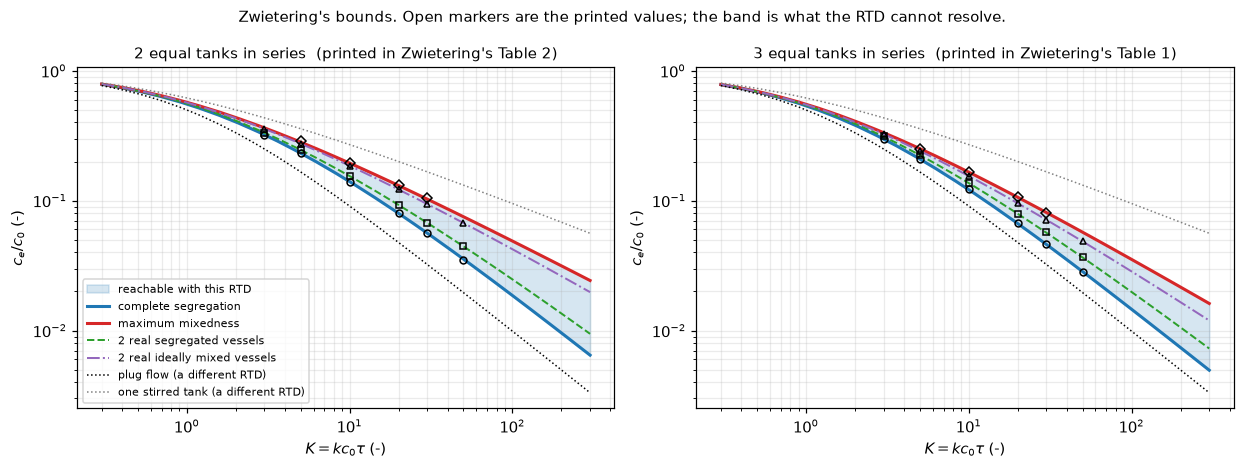

In [9]:
Kgrid = np.logspace(np.log10(0.3), np.log10(300), 26)
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.3))
for ax, n in zip(axes, (2, 3)):
    lo = np.array([gamma_seg(K, n) for K in Kgrid])
    hi = np.array([mm_ode(K, n, X=XDOM) for K in Kgrid])
    ax.fill_between(Kgrid, lo, hi, color="tab:blue", alpha=0.18,
                    label="reachable with this RTD")
    ax.plot(Kgrid, lo, color="tab:blue", lw=2.0, label="complete segregation")
    ax.plot(Kgrid, hi, color="tab:red", lw=2.0, label="maximum mixedness")
    ax.plot(Kgrid, [gamma_real_seg(K, n) for K in Kgrid], color="tab:green", lw=1.3,
            ls="--", label=f"{n} real segregated vessels")
    ax.plot(Kgrid, [gamma_real_mixed(K, n) for K in Kgrid], color="tab:purple", lw=1.3,
            ls="-.", label=f"{n} real ideally mixed vessels")
    ax.plot(Kgrid, 1 / (1 + Kgrid), color="k", lw=1.0, ls=":",
            label="plug flow (a different RTD)")
    ax.plot(Kgrid, (-1 + np.sqrt(1 + 4 * Kgrid)) / (2 * Kgrid), color="grey",
            lw=1.0, ls=":", label="one stirred tank (a different RTD)")
    t = 1 if BODY_N[1] == n else 2
    for row, mk in zip(ROWS, ("o", "s", "^", "D")):
        p = printed(t, row)
        ax.plot(list(p.keys()), list(p.values()), mk, ms=4.5, mfc="none",
                color="k", lw=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$K = k c_0 \tau$ (-)"); ax.set_ylabel(r"$c_e/c_0$ (-)")
    ax.set_title(f"{n} equal tanks in series  (printed in Zwietering's Table {t})",
                 fontsize=9.5)
    ax.grid(alpha=0.25, which="both")
axes[0].legend(fontsize=7.2, loc="lower left")
fig.suptitle("Zwietering's bounds. Open markers are the printed values; "
             "the band is what the RTD cannot resolve.", fontsize=10)
fig.tight_layout()
plt.show()

## Validation

The paper contains no measurement, so every check below is either against a
printed number, against an analytical limit, or against a second computation.

### 1. Two routes to the maximum-mixedness value

The break table further down tests *sensitivity*: whether the answer moves when
something is broken. It cannot test *correctness*: a defect present in both the
model and its own perturbation is invisible to it. What can is a second
computation by another method.

`MaxMixedness` discretises the **conservative** form on a graded finite-volume
grid with van Leer face fluxes and solves the whole profile at once by Newton.
`mm_ode` integrates the **non-conservative** form (eq. 31 as Zwietering writes
it) as an initial-value problem with an adaptive explicit Runge-Kutta method
(Dormand-Prince 8(5,3)), forming no grid and no flux. The equation is contracting
in the backward direction, so it is not stiff there and an explicit method is
legitimate. They share the two RTD functions and the far-field root, and nothing
else. The deferred-correction route solves the same discrete equations as the
Newton route by another iteration; its agreement says only that both iterations
reach the same discrete solution.

In [10]:
REF = {(n, K): mm_ode(K, n, X=XDOM, **REF_TOL) for n in (2, 3) for K in KS}
DEF_GAP = {}
print(f"{'n':>2} {'K':>4} {'pymrm (finite volume)':>22} {'DOP853 (IVP)':>14} {'difference':>11}")
for n in (2, 3):
    for K in KS:
        a, b = MM[(n, K)].exit_value(), REF[(n, K)]
        DEF_GAP[(n, K)] = float(np.max(np.abs(
            MaxMixedness(K, n, X=XDOM, n_cells=NCELL).solve_deferred().g - MM[(n, K)].g)))
        print(f"{n:>2} {K:>4g} {a:22.9f} {b:14.9f} {a - b:+11.2e}")
TWO_ROUTES = max(abs(MM[c].exit_value() - REF[c]) for c in MM)
DEF_GAP_MAX = max(DEF_GAP.values())
BALANCE = max(abs(MM[c].balance_gap()) for c in MM)


def fv_richardson(K, n, cells=(1600, 3200), order=2.0):
    """Richardson limit of the face exit value from two grids, cells doubling."""
    a, b = (gamma_mm(K, n, X=XDOM, n_cells=c, tol=NEWTON_TOL) for c in cells)
    return b + (b - a) / (2 ** order - 1)


RICH = {(K, n): fv_richardson(K, n) for K, n in ((10, 2), (30, 3))}
RICH_GAP = max(abs(RICH[(K, n)] - REF[(n, K)]) for K, n in RICH)
display(Markdown(
    f"Worst disagreement over the {len(MM)} cases: **{TWO_ROUTES:.1e}**, the "
    f"discretisation error of the {NCELL}-cell grid and not a modelling difference: it "
    f"falls at second order under refinement (section 2), and the Richardson limit of "
    f"the 1600- and 3200-cell solves lies within 1e-8 of the reference (here "
    f"{RICH_GAP:.1e}). The worst disagreement is "
    f"{TWO_ROUTES / FIX['mmrow'] * 100:.2f} % of the deviation being measured against "
    f"Zwietering's own maximum-mixedness numbers, so the comparison is limited by "
    f"his arithmetic and not by ours.\n\n"
    f"The deferred-correction route lands on the Newton solution to below 1e-11 in "
    f"every cell of every case (here {DEF_GAP_MAX:.1e}), and the discrete balance, "
    f"outflow at the exit face minus inflow at $x = X$ minus the integrated source, "
    f"closes to below 1e-12 (here {BALANCE:.1e})."))

 n    K  pymrm (finite volume)   DOP853 (IVP)  difference
 2    3            0.363480034    0.363479171   +8.63e-07
 2    5            0.282474371    0.282473633   +7.37e-07
 2   10            0.194687580    0.194686993   +5.87e-07


 2   20            0.130802685    0.130802222   +4.63e-07
 2   30            0.102752681    0.102752280   +4.01e-07
 2   50            0.075284656    0.075284322   +3.34e-07
 3    3            0.333828849    0.333828293   +5.55e-07


 3    5            0.251713901    0.251713514   +3.87e-07
 3   10            0.165833659    0.165833440   +2.19e-07
 3   20            0.106191842    0.106191733   +1.09e-07
 3   30            0.081041005    0.081040940   +6.58e-08


 3   50            0.057218556    0.057218529   +2.65e-08


Worst disagreement over the 12 cases: **8.6e-07**, the discretisation error of the 800-cell grid and not a modelling difference: it falls at second order under refinement (section 2), and the Richardson limit of the 1600- and 3200-cell solves lies within 1e-8 of the reference (here 7.3e-11). The worst disagreement is 0.02 % of the deviation being measured against Zwietering's own maximum-mixedness numbers, so the comparison is limited by his arithmetic and not by ours.

The deferred-correction route lands on the Newton solution to below 1e-11 in every cell of every case (here 4.6e-14), and the discrete balance, outflow at the exit face minus inflow at $x = X$ minus the integrated source, closes to below 1e-12 (here 1.0e-15).

### 2. Both refinement axes, not one

The maximum-mixedness problem has **two** discretisation knobs, and refining only
one measures the wrong thing, the failure recorded on `H1.9` and `J3.1`, where in
both cases the unmeasured axis carried the larger error. Here they are the cell
count $h$ and the domain truncation $X$ at which the far-field root is imposed.
The independent solver adds a third, its tolerance. The full grid ladder is
printed: every rung, both cases, signed errors.

In [11]:
LADDER = (100, 200, 400, 800, 1600, 3200)
CASES = ((10, 2), (30, 3))


def grid_ladder(K, n, limiter=vanleer, ref=None):
    """Signed error of the face exit value on each rung of LADDER."""
    r = REF[(n, K)] if ref is None else ref
    return np.array([gamma_mm(K, n, X=XDOM, n_cells=c, limiter=limiter, tol=NEWTON_TOL) - r
                     for c in LADDER])


def orders(err):
    return np.log2(np.abs(err[:-1] / err[1:]))


GRID = {(K, n, lim): grid_ladder(K, n, limiter=None if lim == "upwind" else vanleer)
        for K, n in CASES for lim in ("van Leer", "upwind")}
print("signed error of gamma(0) against DOP853, and observed order per doubling")
for (K, n, lim), e in GRID.items():
    print(f"K = {K:>2}, n = {n}, {lim:<8}: " + "  ".join(f"{x:+.2e}" for x in e))
    print(f"{'':>24}orders " + "  ".join(f"{o:.3f}" for o in orders(e)))
I400, I800 = LADDER.index(400), LADDER.index(800)
ORD_VL = min(orders(GRID[(K, n, "van Leer")])[I400] for K, n in CASES)
ORD_UW = min(orders(GRID[(K, n, "upwind")])[I400] for K, n in CASES)
ORD_VL_ALL = np.concatenate([orders(GRID[(K, n, "van Leer")])[1:] for K, n in CASES])
SAME_SIGN = all(np.all(np.sign(e) == np.sign(e[0])) for e in GRID.values())

# --- axis 2: domain truncation, on the gridless route --------------------------
K0, N0 = 10, 2
REF_LONG = mm_ode(K0, N0, X=20.0, **REF_TOL)
Xs = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, XDOM])


def truncation(p=2.0):
    ref = mm_ode(K0, N0, X=20.0, p=p, **REF_TOL)
    return np.array([abs(mm_ode(K0, N0, X=X, p=p, **REF_TOL) - ref) for X in Xs])


def decay_rate(tr):
    sel = tr > 1e-13
    return float(-np.polyfit(Xs[sel], np.log(tr[sel]), 1)[0])


TRUNC = truncation()
TRUNC_RATE = decay_rate(TRUNC)
TRUNC_AT_PROD = float(TRUNC[-1])
for X, e in zip(Xs, TRUNC):
    print(f"X = {X:3.1f}: |error| in gamma(0) " + (f"{e:.2e}" if e > 1e-13 else f"(here {e:.1e})"))


def truncation_all(X):
    """Largest |gamma(0; X) - gamma(0; X = 20)| over the printed cases."""
    return max(abs(mm_ode(K, n, X=X, **REF_TOL) - mm_ode(K, n, X=20.0, **REF_TOL))
               for n in (2, 3) for K in KS)


TRUNC_ALL_X4, TRUNC_ALL_PROD = truncation_all(4.0), truncation_all(XDOM)
print(f"worst over the {len(MM)} printed cases: X = 4: {TRUNC_ALL_X4:.1e}; "
      f"X = {XDOM:g}: (here {TRUNC_ALL_PROD:.1e})")

# The decay is predicted, not only fitted. A perturbation imposed at X is damped on
# the way to the exit by exp(-int_0^X mu dx) with mu = d(rhs)/d(gamma) = 2 K gamma
# + E/w, and the far-field error being corrected itself falls like 1/X, because E/w
# approaches its limit n algebraically (E/w = 4x/(1+2x) = 2 - 1/x + ... for two
# tanks). So error(X1)/error(X2) ~ (X2/X1) * exp(int_{X1}^{X2} mu dx).
mu = 2 * K0 * m10.g.ravel() + E_rtd(m10.x_c, N0) / W_rtd(m10.x_c, N0)


def truncation_model(far_field_factor=True):
    rows = []
    for a, b in zip(Xs[1:5], Xs[2:6]):
        s = (m10.x_c >= a) & (m10.x_c <= b)
        damp = np.exp(np.trapezoid(mu[s], m10.x_c[s]))
        obs = TRUNC[list(Xs).index(a)] / TRUNC[list(Xs).index(b)]
        pred = damp * (b / a if far_field_factor else 1.0)
        rows.append((a, b, obs, damp, pred, obs / pred))
    return rows


TMODEL = truncation_model()
TRUNC_MODEL_MAX = max(abs(r[-1] - 1) for r in TMODEL)
print(f"{'X window':<12} {'observed':>9} {'exp(int mu)':>12} {'predicted':>10} {'obs/pred':>9}")
for a, b, obs, damp, pred, r in TMODEL:
    print(f"{a:.1f} -> {b:.1f}   {obs:9.2f} {damp:12.2f} {pred:10.2f} {r:9.3f}")

# --- axis 3: tolerance of the independent solver --------------------------------
REF_TOL_ERR = abs(mm_ode(K0, N0, X=XDOM, rtol=1e-12, atol=1e-14) - REF[(N0, K0)])
GRID_GUARD = min(abs(GRID[(K, n, "van Leer")][I800]) for K, n in CASES) / max(REF_TOL_ERR, 1e-300)
display(Markdown(
    f"**Grid.** With van Leer the error falls at observed order "
    f"{ORD_VL:.2f} from 400 to 800 cells (the smaller of the two cases) and the "
    f"successive orders from 200 cells up lie between {ORD_VL_ALL.min():.2f} and "
    f"{ORD_VL_ALL.max():.2f}; bare upwind gives {ORD_UW:.2f}. "
    + ("Every rung has the same sign, so the ladder is monotone and the 800-cell "
       "error is an error, not a spread. " if SAME_SIGN else
       "The rungs change sign, so the ladder is not monotone. ")
    + f"The 800-cell error is at least {GRID_GUARD:.1e} times the reference's own "
    f"tolerance error, so the orders are not fitted to noise.\n\n"
    f"**Truncation.** The error decays at **{TRUNC_RATE:.2f} per unit** of $X$ "
    f"(fitted where it is above 1e-13) at $K = 10$, two tanks, and reaches the floor set by "
    f"the DOP853 tolerance by $X = 4$ there. Slower cases decay more slowly: over all "
    f"the printed cases the difference is still {TRUNC_ALL_X4:.1e} at $X = 4$ (the "
    f"smallest $K$, two tanks), and at the production $X = {XDOM:g}$ it is below 1e-13 "
    f"in every case (here {TRUNC_ALL_PROD:.1e}), the tolerance floor. The decay is also "
    f"*predicted*: a perturbation imposed at $X$ is damped by "
    f"$\\exp(-\\int_0^X \\mu\\,dx)$ with $\\mu = 2K\\gamma + E/w$, and the far-field "
    f"error itself falls like $1/X$ because $E/w$ approaches $n$ algebraically. "
    f"Observed over predicted lands within **{TRUNC_MODEL_MAX * 100:.0f} %** across the "
    f"{len(TMODEL)} windows.\n\n"
    f"**Tolerance.** The reference at rtol 1e-13 and at 1e-12 agree to below 1e-12 "
    f"(here {REF_TOL_ERR:.1e}), so it is an exact reference at this resolution."))

signed error of gamma(0) against DOP853, and observed order per doubling
K = 10, n = 2, van Leer: +3.83e-05  +9.46e-06  +2.35e-06  +5.87e-07  +1.46e-07  +3.66e-08
                        orders 2.015  2.008  2.004  2.002  2.001
K = 10, n = 2, upwind  : +1.56e-03  +7.76e-04  +3.86e-04  +1.93e-04  +9.62e-05  +4.81e-05
                        orders 1.012  1.006  1.003  1.002  1.001
K = 30, n = 3, van Leer: +5.85e-06  +1.23e-06  +2.78e-07  +6.58e-08  +1.60e-08  +3.95e-09
                        orders 2.254  2.143  2.076  2.039  2.020
K = 30, n = 3, upwind  : +1.65e-03  +8.24e-04  +4.12e-04  +2.06e-04  +1.03e-04  +5.14e-05
                        orders 1.002  1.001  1.001  1.000  1.000


X = 0.5: |error| in gamma(0) 4.10e-03
X = 1.0: |error| in gamma(0) 7.83e-05
X = 1.5: |error| in gamma(0) 1.23e-06
X = 2.0: |error| in gamma(0) 1.74e-08
X = 2.5: |error| in gamma(0) 2.32e-10
X = 3.0: |error| in gamma(0) 2.97e-12
X = 4.0: |error| in gamma(0) (here 4.6e-15)
X = 6.0: |error| in gamma(0) (here 4.1e-15)


worst over the 12 printed cases: X = 4: 3.5e-10; X = 6: (here 9.2e-15)
X window      observed  exp(int mu)  predicted  obs/pred
1.0 -> 1.5       63.73        44.81      67.21     0.948
1.5 -> 2.0       70.56        53.48      71.31     0.989
2.0 -> 2.5       75.08        55.77      69.71     1.077
2.5 -> 3.0       78.20        65.53      78.63     0.994


**Grid.** With van Leer the error falls at observed order 2.00 from 400 to 800 cells (the smaller of the two cases) and the successive orders from 200 cells up lie between 2.00 and 2.14; bare upwind gives 1.00. Every rung has the same sign, so the ladder is monotone and the 800-cell error is an error, not a spread. The 800-cell error is at least 2.5e+06 times the reference's own tolerance error, so the orders are not fitted to noise.

**Truncation.** The error decays at **8.44 per unit** of $X$ (fitted where it is above 1e-13) at $K = 10$, two tanks, and reaches the floor set by the DOP853 tolerance by $X = 4$ there. Slower cases decay more slowly: over all the printed cases the difference is still 3.5e-10 at $X = 4$ (the smallest $K$, two tanks), and at the production $X = 6$ it is below 1e-13 in every case (here 9.2e-15), the tolerance floor. The decay is also *predicted*: a perturbation imposed at $X$ is damped by $\exp(-\int_0^X \mu\,dx)$ with $\mu = 2K\gamma + E/w$, and the far-field error itself falls like $1/X$ because $E/w$ approaches $n$ algebraically. Observed over predicted lands within **8 %** across the 4 windows.

**Tolerance.** The reference at rtol 1e-13 and at 1e-12 agree to below 1e-12 (here 2.6e-14), so it is an exact reference at this resolution.

### 3. The analytical limits, each of which can fail

The limits, in decreasing order of how much they test.

**(a) The exponential RTD.** For a single stirred tank ($n = 1$) Zwietering's
eq. (II, 12) states $\xi(\lambda) = \tau$: the function is constant, so the
maximum-mixedness solution must be constant and equal to the ordinary stirred-tank
root. This is a *degenerate* case: the solution is flat over the whole domain,
and getting the coefficient $E/w$ wrong by any factor breaks it.

**(b) First order.** Zwietering's section 9b: for $R = kc$ every state of mixing
gives the same answer, $\int f(t)e^{-kt}dt$, which for $n$ tanks is
$(1 + K/n)^{-n}$. The segregation quadrature and the backward ODE integration are
different code paths that share only the RTD functions, so the anchor is the
exact closed-form value, not the independence of the two routes.

**(c) Plug flow.** As $n \to \infty$ the RTD narrows to a delta function, which
leaves no freedom for a degree of segregation at all; Zwietering's own footnote:
"the plug flow reactor is at the same time completely segregated and in the state
of maximum mixedness". The bracket must close onto $1/(1+K)$.

**(d) Reaction order.** The bracket must *reverse* through order one, maximum
mixedness giving the least conversion above it and the most below it (his section
1, "the minimum conversion for a reaction of an order higher than one and equally
the maximum conversion for an order of reaction smaller than one").

In [12]:
def lim_cstr(ratio_factor=1.0):
    """Largest |max mixedness, n = 1 - stirred-tank root| over K = 1 to 100."""
    rows = []
    for K in (1, 5, 20, 100):
        rr = None if ratio_factor == 1.0 else (lambda x, f=ratio_factor: f * 1.0)
        mmv, root = mm_ode(K, 1, X=25.0, ratio=rr), gamma_far(K, 1)
        rows.append((K, mmv, root, abs(mmv - root)))
    return rows


LIM_A = lim_cstr()
LIM_CSTR = max(r[-1] for r in LIM_A)
for K, mmv, root, d in LIM_A:
    print(f"n = 1, K = {K:>3}: max mixedness {mmv:.12f}, stirred-tank root {root:.12f}, "
          f"|difference| (here {d:.1e})")


def lim_first_order(ratio=None):
    """First order: (width of the bracket, largest distance to (1 + K/n)^-n)."""
    w, e = [], []
    for n in (2, 3):
        rr = None if ratio is None else ratio(n)
        for K in (5, 30):
            exact = (1 + K / n) ** (-n)
            s, mmv = gamma_seg(K, n, p=1.0), mm_ode(K, n, X=25.0, p=1.0, ratio=rr)
            w.append(abs(mmv - s)); e += [abs(s - exact), abs(mmv - exact)]
    return max(w), max(e)


FIRST_ORDER_WIDTH, FIRST_ORDER_VS_EXACT = lim_first_order()
print(f"first order, n = 2 and 3, K = 5 and 30: bracket width (here {FIRST_ORDER_WIDTH:.1e}), "
      f"distance to (1+K/n)^-n (here {FIRST_ORDER_VS_EXACT:.1e})")


def lim_plug(n_seg=None, X_mm=None, K=30.0):
    rows = []
    for n in (2, 3, 5, 10, 30, 100, 300):
        s = gamma_seg(K, n if n_seg is None else n_seg)
        mmv = mm_ode(K, n, X=max(3.0, 30.0 / n) if X_mm is None else X_mm)
        rows.append((n, s, mmv, (mmv - s) / s, s - 1 / (1 + K)))
    return rows


LIM_C = lim_plug()
PFR_WIDTH_300, PFR_GAP_300 = LIM_C[-1][3], LIM_C[-1][4]
print(f"{'tanks':>6} {'segregation':>12} {'max mixedness':>14} {'rel. width':>11} {'seg - plug':>11}")
for n, s, mmv, w, g in LIM_C:
    print(f"{n:>6} {s:12.6f} {mmv:14.6f} {w:11.4f} {g:11.2e}")


def order_sweep(ps, p_mm=None):
    """(p, segregation, max mixedness) at K = 10, n = 2."""
    return [(p, gamma_seg(10, 2, p=p), mm_ode(10, 2, X=XDOM, p=p if p_mm is None else p_mm))
            for p in ps]


LIM_D = order_sweep((0.5, 0.7, 0.9, 1.0, 1.1, 1.5, 2.0, 3.0))
for p, s, mmv in LIM_D:
    who = ("neither, to round-off" if abs(mmv - s) < 1e-12
           else "maximum mixedness" if mmv < s else "segregation")
    gap = f"(here {mmv - s:+.1e})" if abs(mmv - s) < 1e-12 else f"{mmv - s:+.3e}"
    mms = f"(here {mmv:+.1e})" if abs(mmv) < 1e-10 else f"{mmv:.7f}"
    print(f"p = {p:.1f}: segregation {s:.7f}, max mixedness {mms}, mm - seg {gap}; "
          f"converts more: {who}")
_d = {p: (s, mmv) for p, s, mmv in LIM_D}
ORDER_MARGIN_ABOVE = _d[1.1][1] - _d[1.1][0]
ORDER_MARGIN_BELOW = _d[0.9][1] - _d[0.9][0]
P05_MM, P05_SEG = abs(_d[0.5][1]), _d[0.5][0]

display(Markdown(
    f"**(a)** The exponential-RTD collapse holds to below 1e-12 over two decades of "
    f"$K$ (here {LIM_CSTR:.1e}).\n\n"
    f"**(b)** For a first-order reaction the two bounds coincide to below 1e-12 and both "
    f"sit on $(1+K/n)^{{-n}}$ to below 1e-12 (here {FIRST_ORDER_WIDTH:.1e} and "
    f"{FIRST_ORDER_VS_EXACT:.1e}); the break table shows what corrupting $E/w$ does "
    f"to it.\n\n"
    f"**(c)** The bracket closes onto plug flow: at 300 tanks its relative width is "
    f"**{PFR_WIDTH_300 * 100:.1f} %**, down from {LIM_C[0][3] * 100:.0f} % at two, and the "
    f"segregated value sits {PFR_GAP_300:.1e} above $1/(1+K)$.\n\n"
    f"**(d)** The bracket reverses through order one: at $p = 1.1$ maximum mixedness "
    f"lies {ORDER_MARGIN_ABOVE:+.1e} above segregation and at $p = 0.9$ it lies "
    f"{ORDER_MARGIN_BELOW:+.1e} below it, so which bound is the upper one is decided by "
    f"the order and not by the code. At $p = 0.5$ maximum mixedness drives the exit "
    f"concentration to zero, to below 1e-10 (here {P05_MM:.0e}): complete conversion, which "
    f"for an order below one is reached in finite time, while complete segregation "
    f"leaves {P05_SEG:.4f} unreacted."))

n = 1, K =   1: max mixedness 0.618033988750, stirred-tank root 0.618033988750, |difference| (here 1.8e-14)
n = 1, K =   5: max mixedness 0.358257569496, stirred-tank root 0.358257569496, |difference| (here 3.5e-14)
n = 1, K =  20: max mixedness 0.200000000000, stirred-tank root 0.200000000000, |difference| (here 4.5e-15)
n = 1, K = 100: max mixedness 0.095124921973, stirred-tank root 0.095124921973, |difference| (here 1.9e-15)


first order, n = 2 and 3, K = 5 and 30: bracket width (here 3.5e-14), distance to (1+K/n)^-n (here 3.5e-14)


 tanks  segregation  max mixedness  rel. width  seg - plug
     2     0.056232       0.102752      0.8273    2.40e-02
     3     0.046007       0.081041      0.7615    1.37e-02
     5     0.039521       0.063586      0.6089    7.26e-03
    10     0.035563       0.050078      0.4081    3.31e-03
    30     0.033295       0.039977      0.2007    1.04e-03
   100     0.032563       0.035430      0.0880    3.05e-04
   300     0.032359       0.033646      0.0398    1.01e-04


p = 0.5: segregation 0.0113980, max mixedness (here -2.4e-14), mm - seg -1.140e-02; converts more: maximum mixedness
p = 0.7: segregation 0.0156803, max mixedness 0.0011891, mm - seg -1.449e-02; converts more: maximum mixedness
p = 0.9: segregation 0.0226704, max mixedness 0.0152474, mm - seg -7.423e-03; converts more: maximum mixedness
p = 1.0: segregation 0.0277778, max mixedness 0.0277778, mm - seg (here -4.6e-14); converts more: neither, to round-off
p = 1.1: segregation 0.0343199, max mixedness 0.0426504, mm - seg +8.331e-03; converts more: segregation
p = 1.5: segregation 0.0747135, max mixedness 0.1113209, mm - seg +3.661e-02; converts more: segregation
p = 2.0: segregation 0.1402661, max mixedness 0.1946870, mm - seg +5.442e-02; converts more: segregation
p = 3.0: segregation 0.2622260, max mixedness 0.3258221, mm - seg +6.360e-02; converts more: segregation


**(a)** The exponential-RTD collapse holds to below 1e-12 over two decades of $K$ (here 3.5e-14).

**(b)** For a first-order reaction the two bounds coincide to below 1e-12 and both sit on $(1+K/n)^{-n}$ to below 1e-12 (here 3.5e-14 and 3.5e-14); the break table shows what corrupting $E/w$ does to it.

**(c)** The bracket closes onto plug flow: at 300 tanks its relative width is **4.0 %**, down from 83 % at two, and the segregated value sits 1.0e-04 above $1/(1+K)$.

**(d)** The bracket reverses through order one: at $p = 1.1$ maximum mixedness lies +8.3e-03 above segregation and at $p = 0.9$ it lies -7.4e-03 below it, so which bound is the upper one is decided by the order and not by the code. At $p = 0.5$ maximum mixedness drives the exit concentration to zero, to below 1e-10 (here 2e-14): complete conversion, which for an order below one is reached in finite time, while complete segregation leaves 0.0114 unreacted.

### 4. The degree of segregation, a quantity the reactor solve never touches

$J = \operatorname{var}\alpha_P/\operatorname{var}\alpha$ depends on the RTD and the
state of mixing alone; no reaction enters it. Reproducing the printed values
therefore exercises the age and life-expectation machinery of sections 3 to 7,
which the conversion columns do not.

Several of them have exact closed forms. For $n$ equal tanks, the mean age in
tank $i$ is $i\tau/n$, so $n$ ideally mixed vessels give
$\operatorname{var}\alpha_P = \tau^2(n^2-1)/12n^2$ and, against
$\operatorname{var}\alpha = \tau^2(n+1)(n+5)/12n^2$ from his eq. (11),

$$ J_{\text{ideally mixed}} = \frac{n-1}{n+5} . $$

For $n$ internally segregated vessels a "point" carries a common sojourn in its
current tank but ages accumulated independently over the $i-1$ earlier ones, so
the variance *within* a point is $\tau^2(n-1)/2n^2$ and
$J = 1 - 6(n-1)/\big((n+1)(n+5)\big)$. The maximum-mixedness entries are
quadratures of his eq. (28), and Appendix I's identity, var alpha = var between +
var within, checks those quadratures against a third one, of the ages within a
point.

In [13]:
def J_table(assign, abar_n=None):
    """Computed against printed J, the tables assigned to RTDs by ``assign``."""
    rows = []
    for t in (1, 2):
        n = assign[t]
        ab = None if abar_n is None else (abar_n + 1) / (2 * abar_n)
        got = {"complete_segregation": 1.0, "real_segregated": J_real_seg(n),
               "real_ideally_mixed": J_real_mixed(n),
               "maximum_mixedness": J_mm(n, abar=ab)}
        for r in ROWS:
            p = float(Jdat[(Jdat.table == t) & (Jdat.mixing_state == r)]["J"].iloc[0])
            rows.append({"table": t, "n": n, "row": r, "computed": got[r], "printed": p})
    df = pd.DataFrame(rows)
    df["deviation"] = df["computed"] - df["printed"]
    return df


def J_metrics(df):
    odd = (df.table == 2) & (df.row == "maximum_mixedness")
    mm3 = float(df[odd]["computed"].iloc[0])
    return (float(df["deviation"].abs().max()), float(df[~odd]["deviation"].abs().max()),
            mm3, abs(mm3 / float(df[odd]["printed"].iloc[0]) - 1))


JTAB = J_table(CAP_N)                 # the J column DOES follow the caption
J_MAX, J_MAX_EX, J_MM3, J_MM3_REL = J_metrics(JTAB)
J_MM3_P = float(JTAB[(JTAB.table == 2) & (JTAB.row == "maximum_mixedness")]["printed"].iloc[0])
print(JTAB.to_string(index=False, formatters={"computed": "{:.6f}".format,
                                               "printed": "{:.4f}".format,
                                               "deviation": "{:+.5f}".format}))
RATIONAL = [(Fraction(n - 1, n + 5), "real_ideally_mixed", n) for n in (2, 3)] + \
           [(Fraction((n + 1) * (n + 5) - 6 * (n - 1), (n + 1) * (n + 5)), "real_segregated", n)
            for n in (2, 3)]
J_P = {(r, CAP_N[t]): float(Jdat[(Jdat.table == t) & (Jdat.mixing_state == r)]["J"].iloc[0])
       for t in (1, 2) for r in ROWS}
# the two-tank maximum-mixedness J in closed form, (2e E1(1) - 1)/7, beside
# the quadrature and the printed value (journal page 12 quotes the same 0.0275)
J2_CLOSED = (2 * np.e * exp1(1.0) - 1) / 7
J2_QUAD = float(JTAB[(JTAB.table == 1) & (JTAB.row == "maximum_mixedness")]["computed"].iloc[0])
J2_CLOSED_GAP = abs(J2_QUAD - J2_CLOSED)
print(f"two tanks, maximum mixedness: (2e E1(1) - 1)/7 = {J2_CLOSED:.6f}, quadrature of "
      f"eq. (28) {J2_QUAD:.6f}, printed {J_P[('maximum_mixedness', 2)]:.4f}")

VAR_RESID = max(abs(J_mm(n) * var_alpha(n) + var_within_mm(n) - var_alpha(n)) for n in (2, 3))
J_TOL = 1e-4               # reproduced: within one unit of the printed fourth decimal
J_REPRO = int((JTAB["deviation"].abs() < J_TOL).sum())
display(Markdown(
    f"{J_REPRO} of the {len(JTAB)} reproduce to within {J_TOL:g}: worst "
    f"**{J_MAX_EX:.1e}** among them, {len(RATIONAL)} of them as exact rationals: "
    + ", ".join(f"{fr.numerator}/{fr.denominator} lands on the printed {J_P[(r, n)]:.4f}"
                for fr, r, n in RATIONAL)
    + ". Each lands on the table whose **caption** matches, which is what makes the "
    f"interchange of the conversion bodies an interchange rather than a relabelling. "
    f"The two-tank maximum-mixedness quadrature equals its closed form "
    f"$(2e\\,E_1(1)-1)/7 = {J2_CLOSED:.6f}$ to below 1e-8 (here {J2_CLOSED_GAP:.0e}), and "
    f"that is the {J_P[('maximum_mixedness', 2)]:.4f} journal page 12 calls the "
    f"minimum for the two-vessel distribution.\n\n"
    f"The remaining one does not. The three-tank maximum-mixedness entry computes to "
    f"**{J_MM3:.6f}** against the printed **{J_MM3_P:.4f}**, a {J_MM3_REL * 100:.1f} % "
    f"discrepancy. We cannot explain it and do not repair it; it is reported as an "
    f"unresolved deviation. The quadrature itself is checked twice: its two-tank "
    f"companion meets the closed form above, and Zwietering's Appendix I identity, var "
    f"alpha = var between + var within, closes to below 1e-12 (here {VAR_RESID:.1e}) for "
    f"both RTDs. The identity has only partial power: the two sides share alpha_P, so "
    f"it tests that the age quadratures are consistent with each other and with the "
    f"RTD, not the shape of alpha_P. The break table shows a within-point age "
    f"distribution inconsistent with the RTD breaking it."))

 table  n                  row computed printed deviation
     1  2 complete_segregation 1.000000  1.0000  +0.00000
     1  2      real_segregated 0.714286  0.7143  -0.00001
     1  2   real_ideally_mixed 0.142857  0.1429  -0.00004
     1  2    maximum_mixedness 0.027528  0.0275  +0.00003
     2  3 complete_segregation 1.000000  1.0000  +0.00000
     2  3      real_segregated 0.625000  0.6250  +0.00000
     2  3   real_ideally_mixed 0.250000  0.2500  +0.00000
     2  3    maximum_mixedness 0.080296  0.0831  -0.00280
two tanks, maximum mixedness: (2e E1(1) - 1)/7 = 0.027528, quadrature of eq. (28) 0.027528, printed 0.0275


7 of the 8 reproduce to within 0.0001: worst **4.3e-05** among them, 4 of them as exact rationals: 1/7 lands on the printed 0.1429, 1/4 lands on the printed 0.2500, 5/7 lands on the printed 0.7143, 5/8 lands on the printed 0.6250. Each lands on the table whose **caption** matches, which is what makes the interchange of the conversion bodies an interchange rather than a relabelling. The two-tank maximum-mixedness quadrature equals its closed form $(2e\,E_1(1)-1)/7 = 0.027528$ to below 1e-8 (here 2e-16), and that is the 0.0275 journal page 12 calls the minimum for the two-vessel distribution.

The remaining one does not. The three-tank maximum-mixedness entry computes to **0.080296** against the printed **0.0831**, a 3.4 % discrepancy. We cannot explain it and do not repair it; it is reported as an unresolved deviation. The quadrature itself is checked twice: its two-tank companion meets the closed form above, and Zwietering's Appendix I identity, var alpha = var between + var within, closes to below 1e-12 (here 6.1e-16) for both RTDs. The identity has only partial power: the two sides share alpha_P, so it tests that the age quadratures are consistent with each other and with the RTD, not the shape of alpha_P. The break table shows a within-point age distribution inconsistent with the RTD breaking it.

### 5. Where the bounds bind, and how tight they are

A bound that is never approached is decoration. Two questions decide whether these
are worth anything: how wide is the bracket, and do real reactors actually spread
across it? The second is answerable because Zwietering supplies two *intermediate*
reactors with exactly the same RTD, so their position inside the bracket can be
measured rather than assumed. Define the micromixing position

$$ \mu \;=\; \frac{c_e - c_e^{\text{seg}}}{c_e^{\text{mm}} - c_e^{\text{seg}}}
\;\in\; [0,1] . $$

The maximum-mixedness values are the pymrm solves of the printed cases.

 n  K segregation max mixedness relative width ratio hi/lo mu (real segregated) mu (real ideally mixed)
 2  3     0.32178       0.36348          0.130        1.13                0.279                   0.849
 2  5     0.23235       0.28247          0.216        1.22                0.276                   0.845
 2 10     0.14027       0.19469          0.388        1.39                0.267                   0.836
 2 20     0.07985       0.13080          0.638        1.64                0.252                   0.823
 2 30     0.05623       0.10275          0.827        1.83                0.241                   0.814
 2 50     0.03553       0.07528          1.119        2.12                0.226                   0.802
 3  3     0.29817       0.33383          0.120        1.12                0.366                   0.770
 3  5     0.20942       0.25171          0.202        1.20                0.358                   0.763
 3 10     0.12150       0.16583          0.365        1.36      

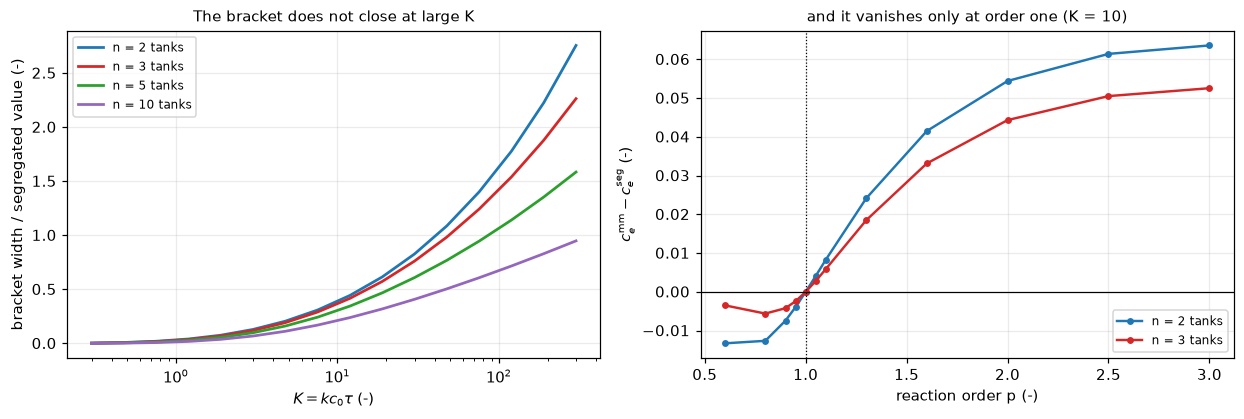

**The bounds bind hard, and they bind harder as the reaction gets faster.** The widest of the printed cases is the two-tank RTD at $K = 50$, where the maximum-mixedness exit concentration is **2.12 times** the segregated one, a relative bracket of 112 %. At $K = 30$ with two tanks it is 83 %. In conversion terms that is the difference between 96.4 % and 92.5 % conversion for one measured RTD.

**And real reactors do occupy the bracket.** Zwietering's two intermediate states run from mu = 0.23 to mu = 0.85 across the cases, spanning 62 % of the band, and the closest either comes to a bound is **0.15** of the bracket width. So neither bound is slack and neither is nearly attained: the band is genuinely the reachable set, not a loose envelope. That is the number that makes the bracketing check able to fail: if the maximum-mixedness solve were wrong by more than 15 % of the bracket in the wrong direction, an intermediate reactor would fall outside it.

In [14]:
def binding(mm=None):
    """The bracket over the printed cases; ``mm`` replaces {(n, K): max mixedness}."""
    rows = []
    for n in (2, 3):
        for K in KS:
            s = gamma_seg(K, n)
            hi = MM[(n, K)].exit_value() if mm is None else mm[(n, K)]
            rs, rm = gamma_real_seg(K, n), gamma_real_mixed(K, n)
            rows.append({"n": n, "K": K, "segregation": s, "max mixedness": hi,
                         "relative width": (hi - s) / s, "ratio hi/lo": hi / s,
                         "mu (real segregated)": (rs - s) / (hi - s),
                         "mu (real ideally mixed)": (rm - s) / (hi - s)})
    b = pd.DataFrame(rows)
    mus = np.concatenate([b["mu (real segregated)"].values, b["mu (real ideally mixed)"].values])
    return b, {"ratio": float(b["ratio hi/lo"].max()),
               "width": float(b["relative width"].max()),
               "width_K30_n2": float(b[(b.n == 2) & (b.K == 30)]["relative width"].iloc[0]),
               "margin": float(min(mus.min(), 1 - mus.max())),
               "mu_min": float(mus.min()), "mu_max": float(mus.max()),
               "mu_span": float(mus.max() - mus.min())}


BIND, BK = binding()
print(BIND.to_string(index=False, formatters={
    "K": "{:g}".format, "segregation": "{:.5f}".format, "max mixedness": "{:.5f}".format,
    "relative width": "{:.3f}".format, "ratio hi/lo": "{:.2f}".format,
    "mu (real segregated)": "{:.3f}".format, "mu (real ideally mixed)": "{:.3f}".format}))

fig, axes = plt.subplots(1, 2, figsize=(11.4, 3.9))
ax = axes[0]
Kw = np.logspace(np.log10(0.3), np.log10(300), 16)
for n, c in ((2, "tab:blue"), (3, "tab:red"), (5, "tab:green"), (10, "tab:purple")):
    w = [(mm_ode(K, n, X=max(3.0, 30.0 / n)) - gamma_seg(K, n)) / gamma_seg(K, n)
         for K in Kw]
    ax.plot(Kw, w, color=c, lw=1.8, label=f"n = {n} tanks")
ax.set_xscale("log"); ax.set_xlabel(r"$K = k c_0 \tau$ (-)")
ax.set_ylabel("bracket width / segregated value (-)")
ax.set_title("The bracket does not close at large K", fontsize=9.5)
ax.grid(alpha=0.25); ax.legend(fontsize=8)

ax = axes[1]
ps = np.array([0.6, 0.8, 0.9, 0.95, 1.0, 1.05, 1.1, 1.3, 1.6, 2.0, 2.5, 3.0])
for n, c in ((2, "tab:blue"), (3, "tab:red")):
    d = [mm_ode(10, n, X=XDOM, p=pp) - gamma_seg(10, n, p=pp) for pp in ps]
    ax.plot(ps, d, "o-", color=c, ms=3.5, lw=1.6, label=f"n = {n} tanks")
ax.axhline(0.0, color="k", lw=0.8); ax.axvline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("reaction order p (-)"); ax.set_ylabel(r"$c_e^{\rm mm} - c_e^{\rm seg}$ (-)")
ax.set_title("and it vanishes only at order one (K = 10)", fontsize=9.5)
ax.grid(alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

_w50 = BIND[(BIND.n == 2) & (BIND.K == 50)].iloc[0]
display(Markdown(
    f"**The bounds bind hard, and they bind harder as the reaction gets faster.** "
    f"The widest of the printed cases is the two-tank RTD at $K = 50$, where the "
    f"maximum-mixedness exit concentration is **{BK['ratio']:.2f} times** the "
    f"segregated one, a relative bracket of {BK['width'] * 100:.0f} %. At $K = 30$ "
    f"with two tanks it is {BK['width_K30_n2'] * 100:.0f} %. In conversion terms that is "
    f"the difference between {100 * (1 - _w50['segregation']):.1f} % and "
    f"{100 * (1 - _w50['max mixedness']):.1f} % conversion for one measured RTD.\n\n"
    f"**And real reactors do occupy the bracket.** Zwietering's two intermediate "
    f"states run from mu = {BK['mu_min']:.2f} to mu = {BK['mu_max']:.2f} across the "
    f"cases, spanning {BK['mu_span'] * 100:.0f} % of the band, and the closest either "
    f"comes to a bound is **{BK['margin']:.2f}** of the bracket width. So neither "
    f"bound is slack and neither is nearly attained: the band is genuinely the "
    f"reachable set, not a loose envelope. That is the number that makes the "
    f"bracketing check able to fail: if the maximum-mixedness solve were wrong by "
    f"more than {BK['margin'] * 100:.0f} % of the bracket in the wrong direction, an "
    f"intermediate reactor would fall outside it."))

### 6. Two traps, measured

**The exit read at the first cell centre** (`A2.6`'s trap), against the face read
the page uses, on a uniform grid and on the graded production grid, both at
$K = 10$, two tanks. And **the far-field boundary value**: replacing the root of
$K\gamma^p + n(\gamma - 1) = 0$ by $\gamma = 1$ at $x = X$, at the production
domain length and at a short one. Both are differences between two pymrm solves
on the same grid, so the grid error cancels from them.

In [15]:
UNI = MaxMixedness(K0, N0, X=XDOM, n_cells=NCELL, grade=1.0).solve(tol=NEWTON_TOL)
CELL_SHIFT_UNI = UNI.exit_cell() - UNI.exit_value()
CELL_SHIFT_GRADED = m10.exit_cell() - m10.exit_value()
print(f"uniform {NCELL} cells: face {UNI.exit_value():.9f}, first cell {UNI.exit_cell():.9f}, "
      f"face error {UNI.exit_value() - REF[(N0, K0)]:+.2e}")
print(f"graded  {NCELL} cells: face {m10.exit_value():.9f}, first cell {m10.exit_cell():.9f}, "
      f"face error {m10.exit_value() - REF[(N0, K0)]:+.2e}")
EXIT_LADDER = (200, 400, 800, 1600, 3200)


def exit_reads(grade=1.0, limiter=vanleer):
    """(cell minus face, face error) on EXIT_LADDER at K = 10, two tanks."""
    out = []
    for c in EXIT_LADDER:
        m = MaxMixedness(K0, N0, X=XDOM, n_cells=c, grade=grade,
                         limiter=limiter).solve(tol=NEWTON_TOL)
        out.append((m.exit_cell() - m.exit_value(), m.exit_value() - REF[(N0, K0)]))
    return np.array(out)


EXIT_UNI = exit_reads()
for c, (sh, fe) in zip(EXIT_LADDER, EXIT_UNI):
    print(f"uniform {c:>4} cells: first cell minus face {sh:+.3e}, face error {fe:+.3e}")
SHIFT_ORD = orders(EXIT_UNI[:, 0])
FACE_ORD = orders(EXIT_UNI[:, 1])
print("orders, cell minus face: " + "  ".join(f"{o:.3f}" for o in SHIFT_ORD))
print("orders, face error:      " + "  ".join(f"{o:.3f}" for o in FACE_ORD))


def farfield_shift(X):
    """gamma(0) with the far-field value 1 minus gamma(0) with the root, same grid."""
    one = gamma_mm(K0, N0, X=X, n_cells=NCELL, far_field="one", tol=NEWTON_TOL)
    return one - gamma_mm(K0, N0, X=X, n_cells=NCELL, tol=NEWTON_TOL)


FAR_X6, FAR_X05 = farfield_shift(XDOM), farfield_shift(0.5)
display(Markdown(
    f"**The cell-centre read.** On a uniform {NCELL}-cell grid, reading the exit at the "
    f"first cell centre instead of the face moves it by {CELL_SHIFT_UNI:+.1e}, "
    f"{abs(CELL_SHIFT_UNI / (UNI.exit_value() - REF[(N0, K0)])):.0f} times that grid's own "
    f"face error. On the uniform ladder the shift falls at observed order "
    f"{SHIFT_ORD.min():.2f} to {SHIFT_ORD.max():.2f} and the face error at "
    f"{FACE_ORD.min():.2f} to {FACE_ORD.max():.2f}: the cell read converges, but at first "
    f"order, so a refinement study of it looks clean while carrying the larger error. "
    f"On the graded grid the first cell is {m10.x_f[1]:.1e} wide and the same "
    f"read moves the exit by {CELL_SHIFT_GRADED:+.1e}, below the grid error. The page "
    f"reads the face anyway, and the discrete balance of validation section 1 closes "
    f"only with the face value.\n\n"
    f"**The far-field value.** At $X = {XDOM:g}$ the defect moves the answer by below "
    f"1e-12 (here {FAR_X6:+.0e}): nothing at all. The backward integration is "
    f"strongly contracting, so by $x = {XDOM:g}$ every trace of the starting value is "
    f"gone. This is Zwietering's own remark ('the solution is very nearly independent "
    f"of the starting point') turned into a measurement, and it means **no check on "
    f"this page has any power over the far-field condition** at the production domain "
    f"length. Shorten the domain to $X = 0.5$ and the same defect moves the answer by "
    f"{FAR_X05:.1e}, which is what shows the insensitivity is a property of the domain "
    f"length and not of the check."))

uniform 800 cells: face 0.194717904, first cell 0.195191952, face error +3.09e-05
graded  800 cells: face 0.194687580, first cell 0.194687966, face error +5.87e-07
uniform  200 cells: first cell minus face +1.709e-03, face error +4.674e-04
uniform  400 cells: first cell minus face +9.152e-04, face error +1.213e-04
uniform  800 cells: first cell minus face +4.740e-04, face error +3.091e-05
uniform 1600 cells: first cell minus face +2.413e-04, face error +7.800e-06
uniform 3200 cells: first cell minus face +1.218e-04, face error +1.959e-06
orders, cell minus face: 0.901  0.949  0.974  0.987
orders, face error:      1.946  1.973  1.986  1.993


**The cell-centre read.** On a uniform 800-cell grid, reading the exit at the first cell centre instead of the face moves it by +4.7e-04, 15 times that grid's own face error. On the uniform ladder the shift falls at observed order 0.90 to 0.99 and the face error at 1.95 to 1.99: the cell read converges, but at first order, so a refinement study of it looks clean while carrying the larger error. On the graded grid the first cell is 9.4e-06 wide and the same read moves the exit by +3.9e-07, below the grid error. The page reads the face anyway, and the discrete balance of validation section 1 closes only with the face value.

**The far-field value.** At $X = 6$ the defect moves the answer by below 1e-12 (here -2e-16): nothing at all. The backward integration is strongly contracting, so by $x = 6$ every trace of the starting value is gone. This is Zwietering's own remark ('the solution is very nearly independent of the starting point') turned into a measurement, and it means **no check on this page has any power over the far-field condition** at the production domain length. Shorten the domain to $X = 0.5$ and the same defect moves the answer by 1.7e-02, which is what shows the insensitivity is a property of the domain length and not of the check.

### Claims: what each number is, and how it is checked

Every number the page stands behind is registered once, in the cell below, with
how it is checked (`docs/claims-design.md` in the gallery repository):

- a **value** is a result whose size is set by physics, by Zwietering's numbers or
  by a discretisation. CI holds it to a relative tolerance of the committed
  baseline, 5 % unless the cell says otherwise;
- a **bound** is a quantity whose size is not physics: a round-off gap between
  two readings of one equation, a solver tolerance, a convergence order. It is
  checked against its stated limits on every run, on every machine, and states
  its basis;
- an **exact** result is a count or a label, checked for equality, with its
  distance to the threshold that decided it.

In [16]:
def value(name, x, rtol=0.05, **kw):
    claims.value(name, x, rtol=rtol, **kw)


def bound(name, x, *, max=None, min=None, basis, note=None, structural=False):
    claims.bound(name, x, max=max, min=min, basis=basis, note=note, structural=structural)


# --- the data -------------------------------------------------------------------
claims.exact("n_printed_conversions", N_CONV)
claims.exact("n_printed_J", N_J)
claims.count("printed_table1_below_table2", ORDER_GAPS, 0.0, min_margin=5e-4, relative=False,
             note="paired cells where Table 1 prints the smaller c_e/c0; margin in c_e/c0")
# --- the interchange, from Zwietering's own printed closed forms --------------------
for row, key in (("complete_segregation", "eq38"), ("real_segregated", "eq3940"),
                 ("real_ideally_mixed", "eq42")):
    for t in (1, 2):
        value(f"{key}_vs_table{t}_max_dev", CLOSED_DEV[(row, t)])
claims.count("closed_forms_landing_on_table2", LAND_LOG, 0.0, min_margin=1.0, relative=False,
             note="log of (deviation from Table 1)/(deviation from Table 2) per closed form")
# --- the printed conversions ----------------------------------------------------------
value("tables_max_dev_interchanged", FIX["max"])
value("tables_rms_dev_interchanged", FIX["rms"])
value("tables_max_dev_as_captioned", CAP["max"])
value("tables_algebraic_rows_max_dev", FIX["alg"])
value("tables_max_mixedness_row_max_dev", FIX["mmrow"])
value("tables_mm3_row_max_dev", FIX["per"][(1, "maximum_mixedness")])
value("tables_readings_max_ratio", CAP["max"] / FIX["max"])
value("tables_readings_rms_ratio", CAP["rms"] / FIX["rms"])
claims.count("tables_within_0p001_interchanged", FIX["dev"], 0.001, above=False,
             min_margin=0.05, note="relative distance of the nearest deviation to 0.001")
claims.count("tables_within_0p001_as_captioned", CAP["dev"], 0.001, above=False,
             min_margin=0.05, note="relative distance of the nearest deviation to 0.001")
claims.exact("tables_outside_0p001_only_mm_2tank", FIX["outside_only_mm2"])
claims.count("tables_algebraic_cells_outside_half_unit", FIX["alg_dev"], 5e-4,
             min_margin=1e-4, note="algebraic cells with |deviation| above 0.0005; relative "
             "distance of the nearest to 0.0005 (4e-6), against quadrature errors near 1e-12")
value("mm_2tank_mean_bias", FIX["bias"][2].mean(), note="printed over computed, minus 1")
value("mm_3tank_mean_bias", FIX["bias"][3].mean(), rtol=0.5,
      note="printed over computed, minus 1; rounding-sized, so a loose tolerance")
claims.count("mm_2tank_deviations_positive", FIX["bias"][2], 0.0, min_margin=1e-3,
             relative=False)
claims.exact("tables_round_to_printed_digits", FIX["rounds"], margin=FIX["round_margin"],
             min_margin=1e-6, note="distance of the nearest computed value to a rounding "
             "boundary, against a grid error below 1e-6")
# --- two routes -------------------------------------------------------------------------
value("mm_pymrm_vs_dop853_max", TWO_ROUTES, note=f"{NCELL} graded cells, {len(MM)} cases")
value("mm_pymrm_vs_dop853_K10_n2", abs(MM[(2, 10)].exit_value() - REF[(2, 10)]),
      note="the case the break rows inject into")
value("mm_route_gap_over_table_dev", TWO_ROUTES / FIX["mmrow"])
bound("mm_richardson_vs_dop853_max", RICH_GAP, max=1e-8, basis="theory",
      note="second-order Richardson on 1600 and 3200 cells, K = 10 n = 2 and K = 30 n = 3")
bound("mm_deferred_vs_newton_max", DEF_GAP_MAX, max=1e-11, basis="tolerance",
      note=f"largest cell gap, {len(MM)} cases; Newton tol 1e-11, sweeps to 1e-13")
bound("mm_balance_gap_face", BALANCE, max=1e-12, basis="identity",
      note="conservative fluxes telescope; exit read on the face")
# --- refinement ----------------------------------------------------------------------------
bound("mm_grid_order_vanleer", ORD_VL, min=1.9, max=2.1, basis="theory",
      note="400 to 800 cells, smaller of the two cases")
bound("mm_grid_order_vanleer_min", ORD_VL_ALL.min(), min=1.95, max=2.25, basis="theory",
      note="successive orders from 200 cells, both cases; pre-asymptotic above 2")
bound("mm_grid_order_vanleer_max", ORD_VL_ALL.max(), min=1.95, max=2.25, basis="theory",
      note="successive orders from 200 cells, both cases; pre-asymptotic above 2")
bound("mm_grid_order_upwind", ORD_UW, min=0.95, max=1.05, basis="theory",
      note="400 to 800 cells, first-order upwind")
claims.exact("mm_grid_ladder_same_sign", SAME_SIGN)
bound("mm_grid_finest_over_ref_tolerance", GRID_GUARD, min=1e3, basis="theory",
      note="800-cell error over the reference's tolerance error")
value("mm_truncation_decay_rate", TRUNC_RATE)
bound("mm_truncation_error_at_X6", TRUNC_AT_PROD, max=1e-13, basis="tolerance",
      note="K = 10, n = 2: DOP853 tolerance floor, X = 6 against X = 20")
bound("mm_truncation_error_at_X6_all_cases", TRUNC_ALL_PROD, max=1e-13, basis="tolerance",
      note="worst over the printed cases, X = 6 against X = 20")
value("mm_truncation_error_at_X4_all_cases", TRUNC_ALL_X4,
      note="worst over the printed cases, X = 4 against X = 20")
value("mm_truncation_model_max_rel_err", TRUNC_MODEL_MAX, rtol=0.1)
bound("mm_reference_tolerance_error", REF_TOL_ERR, max=1e-12, basis="tolerance",
      note="DOP853 at rtol 1e-12 against 1e-13")
# --- analytical limits ------------------------------------------------------------------------
bound("limit_exponential_rtd_max_dev", LIM_CSTR, max=1e-12, basis="tolerance")
bound("limit_first_order_bracket_width", FIRST_ORDER_WIDTH, max=1e-12, basis="tolerance")
bound("limit_first_order_vs_exact", FIRST_ORDER_VS_EXACT, max=1e-12, basis="tolerance")
value("limit_plugflow_rel_width_n300", PFR_WIDTH_300)
value("limit_plugflow_seg_gap_n300", PFR_GAP_300)
value("order_margin_p_1p1", ORDER_MARGIN_ABOVE)
value("order_margin_p_0p9", ORDER_MARGIN_BELOW)
bound("limit_order_half_mm_exit", P05_MM, max=1e-10, basis="tolerance",
      note="order 0.5 exhausts in finite time; DOP853 atol 1e-14")
value("limit_order_half_seg", P05_SEG)
# --- degree of segregation ------------------------------------------------------------------------
value("J_max_dev_seven_of_eight", J_MAX_EX)
claims.count("J_reproduced_within_1e-4", JTAB["deviation"].abs(), J_TOL, above=False,
             min_margin=0.05, note="relative distance of the nearest deviation to 1e-4")
value("J_max_dev_all_eight", J_MAX)
value("J_mm_3tank_computed", J_MM3, rtol=1e-4)
value("J_mm_3tank_rel_discrepancy", J_MM3_REL)
bound("J_mm_2tank_vs_closed_form", J2_CLOSED_GAP, max=1e-8, basis="tolerance",
      note="quadrature of eq. (28) against (2e E1(1) - 1)/7")
bound("J_variance_identity_residual", VAR_RESID, max=1e-12, basis="identity",
      note="Appendix I: var alpha = var between + var within, n = 2 and 3")
# --- the bracket ------------------------------------------------------------------------------------
value("bracket_max_ratio_hi_over_lo", BK["ratio"], rtol=0.01)
value("bracket_max_relative_width", BK["width"])
value("bracket_rel_width_K30_n2", BK["width_K30_n2"])
value("bracket_min_margin_of_interior", BK["margin"])
value("bracket_mu_min", BK["mu_min"])
value("bracket_mu_max", BK["mu_max"], rtol=0.01)
value("bracket_mu_span", BK["mu_span"])
# --- the traps --------------------------------------------------------------------------------------
value("break_exit_cell_uniform_grid", abs(CELL_SHIFT_UNI), note="first cell minus face, uniform")
value("exit_cell_shift_graded", abs(CELL_SHIFT_GRADED), note="first cell minus face, graded")
bound("exit_cell_shift_order_uniform_min", SHIFT_ORD.min(), min=0.85, max=1.1, basis="theory",
      note="first cell minus face, uniform grids 200 to 3200 cells; pre-asymptotic below 1")
bound("exit_cell_shift_order_uniform_max", SHIFT_ORD.max(), min=0.85, max=1.1, basis="theory",
      note="first cell minus face, uniform grids 200 to 3200 cells; pre-asymptotic below 1")
bound("exit_face_order_uniform_min", FACE_ORD.min(), min=1.9, max=2.1, basis="theory",
      note="face error, uniform grids 200 to 3200 cells")
bound("break_farfield_root_shift", abs(FAR_X6), max=1e-12, basis="chosen",
      note="far-field value 1 against the root at X = 6: the contraction leaves round-off")
value("break_farfield_root_shift_X0p5", abs(FAR_X05), note="the same at X = 0.5")
print(f"{len(claims.metrics)} claims so far: "
      + ", ".join(f"{sum(c['kind'] == k for c in claims.metrics.values())} {k}"
                  for k in ("value", "bound", "exact")))

74 claims so far: 41 value, 21 bound, 12 exact


### Break table: what each reported number is sensitive to

Each row breaks one thing on purpose, **re-runs** the computation behind one or
more claims with the defect in place (a changed argument of the same function,
never a typed number), and hands the result to `claims.breaks`, which records
whether the claim's own check (its tolerance or its bound) catches it. Every
claim must be failed by at least one row, and the last cell of the page raises
otherwise. A defect that leaves the solver without a solution is recorded as
`nan`, and the note says whether the discrete equations have one.

The last column of the first table is the check Zwietering's bounds provide: for
the defects injected into the maximum-mixedness solve at $K = 10$, two tanks,
whether the intermediate reactor with the same RTD still lies inside the resulting
bracket.

In [17]:
BREAK = []


def brk(name, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(name, metric, broken)
    BREAK.append((name, metric, claims[metric], float(broken), caught))


def fv(**kw):
    """gamma(0) at K = 10, two tanks, with a defect; nan when Newton fails."""
    args = dict(X=XDOM, n_cells=NCELL, tol=NEWTON_TOL)
    args.update(kw)
    try:
        return gamma_mm(K0, N0, **args)
    except RuntimeError:
        return np.nan


def kwlabel(kw):
    return ", ".join(f"{k}={getattr(v, '__name__', v)}" for k, v in kw.items())


LO, RM = gamma_seg(K0, N0), gamma_real_mixed(K0, N0)
REF0 = REF[(N0, K0)]
# --- the maximum-mixedness solve: physics and discretisation defects -----------------
PHYS = [dict(rxn_sign=-1.0), dict(feed=False), dict(v_const=True), dict(p=1.0)]
DISC = [dict(X=0.5), dict(X=1.0), dict(n_cells=25), dict(grade=1.0), dict(limiter=None),
        dict(n_cells=400)]
print(f"{'defect in MaxMixedness, K = 10, n = 2':<40} {'gamma(0)':>12} {'shift':>10}  interior inside")
for kw in PHYS + DISC:
    v = fv(**kw)
    inside = bool(np.isfinite(v) and LO <= RM <= v)
    shown = f"{v:12.6f}" if np.isfinite(v) else f"{'no solution':>12}"
    print(f"{kwlabel(kw):<40} {shown} {v - REF0:+10.2e}  {inside}")
    brk(kwlabel(kw), "mm_pymrm_vs_dop853_K10_n2", abs(v - REF0))
# The flipped sign has no steady solution at all. Eq. (31) is first order with one
# inflow condition, so the backward initial-value solution from x = X is the only
# candidate, and with the sign flipped it blows up: dgamma/d(-x) = K gamma^2 - r
# (gamma - 1) with r = E/w. Three ways to see it, none of them the Newton failure.
def flip_blowup_dop853(X):
    """x at which DOP853 stops on eq. (31) with the reaction sign flipped."""
    s = solve_ivp(lambda x, y: -K0 * y[0] ** 2 + E_rtd(np.atleast_1d(x), N0)[0]
                  / W_rtd(x, N0) * (y[0] - 1.0), (X, 0.0), [gamma_far(K0, N0)],
                  method="DOP853", rtol=1e-12, atol=1e-14)
    return float(s.t[-1]) if s.status == -1 else np.nan


def flip_blowup_riccati(X):
    """Blow-up position with r frozen at its value at X: X - int dg/(K g^2 - r g + r)."""
    r = float(E_rtd(np.array([X]), N0)[0] / W_rtd(X, N0))
    return X - quad(lambda g: 1.0 / (K0 * g * g - r * g + r), gamma_far(K0, N0), np.inf)[0]


def flip_far_discriminant(K):
    """Discriminant of the flipped far-field equation K g^2 - n g + n = 0."""
    return N0 * N0 - 4 * K * N0


FLIP_X, FLIP_RIC, FLIP_DISC = flip_blowup_dop853(XDOM), flip_blowup_riccati(XDOM), \
    flip_far_discriminant(K0)
print(f"rxn_sign=-1 in eq. (31) itself: DOP853 from x = {XDOM:g} stops at x = {FLIP_X:.2f}; "
      f"the frozen-coefficient Riccati equation blows up at x = {FLIP_RIC:.3f}; the flipped "
      f"far-field equation has discriminant {FLIP_DISC:g}, so no real far-field value")
_fwd = solve_ivp(lambda x, y: K0 * max(y[0], 0.0) ** 2 + E_rtd(np.atleast_1d(x), N0)[0]
                 / W_rtd(x, N0) * (y[0] - 1.0), (0.0, XDOM), [REF0], method="DOP853",
                 rtol=1e-12, atol=1e-14)
print(f"eq. (31) integrated forward from the exact gamma(0): stops at x = {_fwd.t[-1]:.2f} "
      f"with gamma {_fwd.y[0, -1]:.1e}")
value("flip_blowup_x_dop853", FLIP_X, rtol=0.01)
value("flip_blowup_x_riccati", FLIP_RIC, rtol=0.01)
claims.exact("flip_farfield_discriminant", int(FLIP_DISC))
brk("integration started at X=4", "flip_blowup_x_dop853", flip_blowup_dop853(4.0))
brk("integration started at X=4", "flip_blowup_x_riccati", flip_blowup_riccati(4.0))
brk("K=0.4", "flip_farfield_discriminant", flip_far_discriminant(0.4))
brk("reference: eq. (31) integrated forward from x = 0", "mm_pymrm_vs_dop853_K10_n2",
    abs(MM[(N0, K0)].exit_value() - mm_ode(K0, N0, X=XDOM, backward=False, g_start=REF0)))
_cst = mm_ode(K0, N0, X=XDOM, ratio=lambda x: float(N0))
brk("reference: E/w replaced by its far-field constant n", "mm_pymrm_vs_dop853_K10_n2",
    abs(MM[(N0, K0)].exit_value() - _cst))
_gap400 = max(abs(gamma_mm(K, n, X=XDOM, n_cells=400, tol=NEWTON_TOL) - REF[(n, K)])
              for n, K in MM)
brk("n_cells=400 in every case", "mm_pymrm_vs_dop853_max", _gap400)
brk("n_cells=400 in every case", "mm_route_gap_over_table_dev", _gap400 / FIX["mmrow"])
brk("Richardson with order 1", "mm_richardson_vs_dop853_max",
    max(abs(fv_richardson(K, n, order=1.0) - REF[(n, K)]) for K, n in CASES))
_dlo = max(float(np.max(np.abs(MaxMixedness(K, n, X=XDOM, n_cells=NCELL).solve_deferred(
    tol=1e-6).g - MM[(n, K)].g))) for n, K in ((2, 10), (3, 30)))
brk("deferred correction stopped at sweep change 1e-6", "mm_deferred_vs_newton_max", _dlo)
brk("exit read at the first cell centre", "mm_balance_gap_face",
    max(abs(MM[c].balance_gap(MM[c].exit_cell())) for c in MM))
# --- refinement ------------------------------------------------------------------------------
_uw = {c: GRID[(c[0], c[1], "upwind")] for c in CASES}
brk("limiter=None in the van Leer ladder", "mm_grid_order_vanleer",
    min(orders(_uw[c])[I400] for c in CASES))
brk("limiter=None in the van Leer ladder", "mm_grid_order_vanleer_min",
    np.concatenate([orders(_uw[c])[1:] for c in CASES]).min())
brk("limiter=None in the van Leer ladder", "mm_grid_order_vanleer_max",
    np.concatenate([orders(_uw[c])[1:] for c in CASES]).max())
brk("limiter=vanleer in the upwind ladder", "mm_grid_order_upwind", ORD_VL)
_shift = {c: grid_ladder(*c, ref=REF[(c[1], c[0])] + 1e-6) for c in CASES}
brk("reference shifted by 1e-6", "mm_grid_ladder_same_sign",
    all(np.all(np.sign(e) == np.sign(e[0])) for e in _shift.values()))
_loose = abs(mm_ode(K0, N0, X=XDOM, rtol=1e-6, atol=1e-8) - REF[(N0, K0)])
brk("reference at rtol 1e-6", "mm_grid_finest_over_ref_tolerance",
    min(abs(GRID[(K, n, "van Leer")][I800]) for K, n in CASES) / _loose)
brk("reference at rtol 1e-6", "mm_reference_tolerance_error", _loose)
brk("p=1 in the truncation sweep", "mm_truncation_decay_rate", decay_rate(truncation(p=1.0)))
brk("production X=1.0", "mm_truncation_error_at_X6",
    abs(mm_ode(K0, N0, X=1.0, **REF_TOL) - REF_LONG))
brk("production X=4.0", "mm_truncation_error_at_X6_all_cases", TRUNC_ALL_X4)
brk("X=3.0 instead of 4", "mm_truncation_error_at_X4_all_cases", truncation_all(3.0))
brk("prediction without the 1/X far-field factor", "mm_truncation_model_max_rel_err",
    max(abs(r[-1] - 1) for r in truncation_model(far_field_factor=False)))
# --- analytical limits -------------------------------------------------------------------------
brk("E/w doubled for one tank", "limit_exponential_rtd_max_dev",
    max(r[-1] for r in lim_cstr(ratio_factor=2.0)))
_fo_const = lim_first_order(ratio=lambda n: (lambda x: float(n)))
_fo_three = lim_first_order(ratio=lambda n: (lambda x: float(E_rtd(np.atleast_1d(x), n + 1)[0]
                                                            / W_rtd(x, n + 1))))
brk("E/w replaced by its far-field constant n", "limit_first_order_bracket_width", _fo_const[0])
brk("E/w of n + 1 tanks with the n-tank RTD", "limit_first_order_bracket_width", _fo_three[0])
brk("E/w replaced by its far-field constant n", "limit_first_order_vs_exact", _fo_const[1])
brk("max mixedness from X=1.0 at every n", "limit_plugflow_rel_width_n300",
    lim_plug(X_mm=1.0)[-1][3])
brk("segregation with the 100-tank RTD at every n", "limit_plugflow_seg_gap_n300",
    lim_plug(n_seg=100)[-1][4])
_sw = order_sweep((0.9, 1.1), p_mm=1.0)
brk("max mixedness at order 1 in the order sweep", "order_margin_p_1p1",
    [m - s for p, s, m in _sw if p == 1.1][0])
brk("max mixedness at order 1 in the order sweep", "order_margin_p_0p9",
    [m - s for p, s, m in _sw if p == 0.9][0])
_p07 = order_sweep((0.7,))[0]
brk("order 0.7 instead of 0.5", "limit_order_half_mm_exit", abs(_p07[2]))
brk("order 0.7 instead of 0.5", "limit_order_half_seg", _p07[1])
# --- the interchange and the printed tables -------------------------------------------------------
for row, key in (("complete_segregation", "eq38"), ("real_segregated", "eq3940"),
                 ("real_ideally_mixed", "eq42")):
    for t in (1, 2):
        brk(f"closed form compared with Table {3 - t}", f"{key}_vs_table{t}_max_dev",
            closed_dev(row, 3 - t))
brk("closed forms compared with the other table", "closed_forms_landing_on_table2",
    int(sum(np.log(CLOSED_DEV[(r, 2)] / CLOSED_DEV[(r, 1)]) > 0 for r in CLOSED)))
_drop = conv[conv.mixing_state != "maximum_mixedness"]
brk("maximum-mixedness rows dropped on loading", "n_printed_conversions", len(_drop))
brk("maximum-mixedness rows dropped on loading", "n_printed_J",
    len(Jdat[Jdat.mixing_state != "maximum_mixedness"]))
brk("ordering taken within Table 1", "printed_table1_below_table2",
    int((ordering(1, 1) > 0).sum()))
for metric, key in (("tables_max_dev_interchanged", "max"), ("tables_rms_dev_interchanged", "rms"),
                    ("tables_algebraic_rows_max_dev", "alg"),
                    ("tables_max_mixedness_row_max_dev", "mmrow")):
    brk("tables assigned as captioned", metric, CAP[key])
brk("tables assigned as captioned", "tables_mm3_row_max_dev", CAP["per"][(2, "maximum_mixedness")])
brk("tables assigned as interchanged", "tables_max_dev_as_captioned", FIX["max"])
_both = summary(BODY_N)
brk("both readings assigned as interchanged", "tables_readings_max_ratio",
    _both["max"] / FIX["max"])
brk("both readings assigned as interchanged", "tables_readings_rms_ratio",
    _both["rms"] / FIX["rms"])
brk("tables assigned as captioned", "tables_within_0p001_interchanged",
    int((CAP["dev"] <= 0.001).sum()))
brk("tables assigned as interchanged", "tables_within_0p001_as_captioned",
    int((FIX["dev"] <= 0.001).sum()))
brk("tables assigned as captioned", "tables_outside_0p001_only_mm_2tank", CAP["outside_only_mm2"])
brk("tables assigned as captioned", "tables_algebraic_cells_outside_half_unit", CAP["alg_half"])
brk("tables assigned as captioned", "mm_2tank_mean_bias", CAP["bias"][2].mean())
brk("tables assigned as captioned", "mm_3tank_mean_bias", CAP["bias"][3].mean())
brk("tables assigned as captioned", "mm_2tank_deviations_positive", int((CAP["bias"][2] > 0).sum()))
brk("tables assigned as captioned", "tables_round_to_printed_digits", CAP["rounds"])
# --- degree of segregation --------------------------------------------------------------------------
_jb = J_metrics(J_table(BODY_N))
brk("J column assigned as the conversion bodies", "J_max_dev_all_eight", _jb[0])
brk("J column assigned as the conversion bodies", "J_max_dev_seven_of_eight", _jb[1])
_jbt = J_table(BODY_N)
brk("J column assigned as the conversion bodies", "J_reproduced_within_1e-4",
    int((_jbt["deviation"].abs() < J_TOL).sum()))
_ja = J_metrics(J_table(CAP_N, abar_n=2))
brk("mean age of two tanks in eq. (28)", "J_mm_3tank_computed", _ja[2])
brk("mean age of two tanks in eq. (28)", "J_mm_3tank_rel_discrepancy", _ja[3])
brk("mean age of three tanks in eq. (28) for two tanks", "J_mm_2tank_vs_closed_form",
    abs(J_mm(2, abar=4 / 6) - J2_CLOSED))
_f3 = lambda y: E_rtd(np.array([y]), 3)[0]
brk("within-point ages from the 3-tank density, n = 2", "J_variance_identity_residual",
    abs(J_mm(2) * var_alpha(2) + var_within_mm(2, density=_f3) - var_alpha(2)))
# --- the bracket ----------------------------------------------------------------------------------------
_bv = binding(mm={(n, K): gamma_mm(K, n, X=XDOM, n_cells=NCELL, v_const=True, tol=NEWTON_TOL)
                  for n, K in MM})[1]
for metric, key in (("bracket_max_ratio_hi_over_lo", "ratio"),
                    ("bracket_max_relative_width", "width"),
                    ("bracket_rel_width_K30_n2", "width_K30_n2"),
                    ("bracket_min_margin_of_interior", "margin"), ("bracket_mu_min", "mu_min"),
                    ("bracket_mu_max", "mu_max"), ("bracket_mu_span", "mu_span")):
    brk("v_const=True in every case", metric, _bv[key])
# --- the traps ----------------------------------------------------------------------------------------
brk("graded grid instead of uniform", "break_exit_cell_uniform_grid", abs(CELL_SHIFT_GRADED))
brk("uniform grid instead of graded", "exit_cell_shift_graded", abs(CELL_SHIFT_UNI))
_exg = exit_reads(grade=2.0)
brk("grade=2.0 ladder instead of uniform", "exit_cell_shift_order_uniform_min",
    orders(_exg[:, 0]).min())
brk("grade=2.0 ladder instead of uniform", "exit_cell_shift_order_uniform_max",
    orders(_exg[:, 0]).max())
brk("limiter=None on the uniform ladder", "exit_face_order_uniform_min",
    orders(exit_reads(limiter=None)[:, 1]).min())
brk("domain X=0.5 instead of 6", "break_farfield_root_shift", abs(FAR_X05))
brk("domain X=1.0 instead of 0.5", "break_farfield_root_shift_X0p5", abs(farfield_shift(1.0)))

print(f"\n{'injected defect':<54} {'claim':<36} {'clean':>16} {'broken':>16}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.1e})" if is_bound else f"{clean:10.4g}"
    broke = f"{broken:10.4g}"
    print(f"{name[:54]:<54} {metric[:36]:<36} {shown:>16} {broke:>16}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: " + (", ".join(f"{n} -> {m}" for n, m in _uncaught)
                                               or "none"))

defect in MaxMixedness, K = 10, n = 2        gamma(0)      shift  interior inside


rxn_sign=-1.0                             no solution       +nan  False
feed=False                                   0.000010  -1.95e-01  False
v_const=True                                 0.219758  +2.51e-02  True
p=1.0                                        0.027778  -1.67e-01  False
X=0.5                                        0.198792  +4.10e-03  True
X=1.0                                        0.194765  +7.84e-05  True
n_cells=25                                   0.195337  +6.50e-04  True
grade=1.0                                    0.194718  +3.09e-05  True


limiter=None                                 0.194880  +1.93e-04  True
n_cells=400                                  0.194689  +2.35e-06  True


rxn_sign=-1 in eq. (31) itself: DOP853 from x = 6 stops at x = 5.76; the frozen-coefficient Riccati equation blows up at x = 5.760; the flipped far-field equation has discriminant -76, so no real far-field value


eq. (31) integrated forward from the exact gamma(0): stops at x = 4.03 with gamma 8.3e+11



injected defect                                        claim                                           clean           broken  caught
rxn_sign=-1.0                                          mm_pymrm_vs_dop853_K10_n2                   5.867e-07              nan  yes
feed=False                                             mm_pymrm_vs_dop853_K10_n2                   5.867e-07           0.1947  yes
v_const=True                                           mm_pymrm_vs_dop853_K10_n2                   5.867e-07          0.02507  yes
p=1.0                                                  mm_pymrm_vs_dop853_K10_n2                   5.867e-07           0.1669  yes
X=0.5                                                  mm_pymrm_vs_dop853_K10_n2                   5.867e-07         0.004105  yes
X=1.0                                                  mm_pymrm_vs_dop853_K10_n2                   5.867e-07        7.843e-05  yes
n_cells=25                                             mm_pymrm_vs_dop853_K10_n

**Reading the first table.** Deleting the side feed or dropping to first order
pushes the answer below the interior reactor, so the bracketing check catches
both on its own. The face velocity $-1$ instead of $-(1-F)$ moves the answer up,
and the bracket cannot see it. With the reaction sign flipped there is no
steady solution to find. Eq. (31) is first order with one inflow condition, so
the backward initial-value solution from $x = X$ is the only candidate, and with
the sign flipped it blows up: DOP853 stops a short distance below $X$, the
Riccati equation with $E/w$ frozen at its value at $X$ blows up at the same
place, and the flipped far-field equation has no real root at all (the printed
line gives all three). Newton's failure only agrees with this. That row is
caught by the absence of a solution, not by a comparison; an upper bound that is
too high cannot be caught by something it bounds, so the bracket would not see a
milder version of it either. What catches upward defects is the comparison
with the gridless route and with the printed tables. Integrating eq. (31) forward
instead of backward does not give a wrong answer, it gives none: the equation is
unstable in that direction, which is the reason Zwietering's construction starts
at large $\lambda$.

## What pymrm adds

**To the physics, nothing.** Zwietering's bounds are right, his four mixing states
are correctly formulated, and his printed conversions are reproduced to the
precision measured in the Results section above. This page adds no term to
eq. (31) and no state of mixing he did not define.

What it adds is arithmetic he had to do by hand, and three things that follow from
being able to do it cheaply.

1. **The dashes in each maximum-mixedness row are filled in.** Zwietering
   integrated eq. (31) only for the values of $K$ the data cell lists; at the
   others the tables carry a dash. Those values are computed below. They are an
   extension, not agreement, and are labelled as such.
2. **The size of his own integration error is measurable.** Only one row in
   either table sits outside one unit of his last decimal (0.001), and it is the
   one row he had to integrate by hand. The bias is computed above, not asserted.
3. **The interchange of the two tables' conversion bodies** is visible only once
   every value can be recomputed in a second.

**And the conservative discretisation is the pymrm-shaped part.** Eq. (31) is
usually presented, and usually solved, as an initial-value problem. Written as
$\operatorname{div}(v\gamma) = E - Kw\gamma^p$ with $v = -w$ it is an ordinary
convection-reaction boundary-value problem with a decaying velocity field and a
distributed feed: the same operator stack as a plug-flow reactor with side
injection, `construct_convflux_upwind` and `construct_div`, van Leer face fluxes
with their exact Jacobian from `ConvFluxTVD`, and `newton`. That reframing makes
the life-expectation coordinate behave like any other spatial axis: the van Leer
solve converges at second order on the graded grid, conserves the side feed to
round-off when the exit is read on the face, and needs a handful of Newton
iterations (the implementation cell prints them beside the deferred-correction
sweeps).

It is not the faster or the more accurate route for this scalar equation: the
gridless DOP853 integration at a loose tolerance is as fast and more accurate
than the 800-cell solve (the implementation cell prints times and errors of
both), and every number on this page could have been computed without a grid.
What the conservative finite-volume form adds is a discrete balance that closes
to round-off, the whole profile as one Newton system, and the operator stack a
reactor model with side feeds, a second phase or a measured RTD on a grid would
reuse, where an initial-value march is no longer available.

In [18]:
fill = []
for t in (1, 2):
    n = BODY_N[t]
    for K in DASH_KS:
        s, hi = gamma_seg(K, n), MM[(n, K)].exit_value()
        fill.append({"Zwietering's table": t, "caption says": f"{CAP_N[t]} tanks",
                     "RTD the body is": f"{n} tanks", "K": K,
                     "segregation (printed)": printed(t, "complete_segregation")[K],
                     "segregation (computed)": s, "maximum mixedness (NOT printed)": hi,
                     "bracket width / segregated": (hi - s) / s})
fdf = pd.DataFrame(fill)
print(fdf.to_string(index=False, formatters={
    "K": "{:g}".format, "segregation (printed)": "{:.3f}".format,
    "segregation (computed)": "{:.5f}".format,
    "maximum mixedness (NOT printed)": "{:.4f}".format,
    "bracket width / segregated": "{:.3f}".format}))
for _, r in fdf.iterrows():
    tag = f"K{r['K']:g}_{r['RTD the body is'][0]}tank"
    value(f"filled_dash_mm_{tag}", r["maximum mixedness (NOT printed)"], rtol=1e-4)
    value(f"filled_dash_width_{tag}", r["bracket width / segregated"], rtol=1e-4,
          note="computed segregation, same basis as the maximum-mixedness value")
    n = int(r["RTD the body is"][0])
    _up = gamma_mm(r["K"], n, X=XDOM, n_cells=NCELL, limiter=None, tol=NEWTON_TOL)
    brk("limiter=None", f"filled_dash_mm_{tag}", _up)
    _sp = r["segregation (printed)"]
    brk("segregation from the printed table", f"filled_dash_width_{tag}",
        (r["maximum mixedness (NOT printed)"] - _sp) / _sp)
FILLED_K50_N2 = float(fdf[(fdf["RTD the body is"] == "2 tanks") & (fdf.K == 50)]
                      ["maximum mixedness (NOT printed)"].iloc[0])
_s50 = float(fdf[(fdf["RTD the body is"] == "2 tanks") & (fdf.K == 50)]
             ["segregation (computed)"].iloc[0])
display(Markdown(
    f"The dash at $K = 50$ for the two-tank RTD is **{FILLED_K50_N2:.4f}**, against "
    f"{_s50:.4f} for complete segregation in the same column (printed "
    f"{printed(2, 'complete_segregation')[50]:.3f}): the widest bracket in either "
    f"table, and the one Zwietering stopped short of. The bracket widths in the table "
    f"divide by the computed segregated value, the same basis as the "
    f"maximum-mixedness value."))
_uc = [(n, m) for n, m, _, _, c in BREAK if not c]
_cc = {m for _, m, _, _, c in BREAK if c}
print(f"{len(BREAK)} break rows in all; {len(_cc)} of {len(claims.metrics)} claims are failed "
      f"by at least one row; rows that do not fail their claim: "
      + (", ".join(f"{n} -> {m}" for n, m in _uc) or "none"))

 Zwietering's table caption says RTD the body is  K segregation (printed) segregation (computed) maximum mixedness (NOT printed) bracket width / segregated
                  1      2 tanks         3 tanks  3                 0.298                0.29817                          0.3338                      0.120
                  1      2 tanks         3 tanks 50                 0.028                0.02846                          0.0572                      1.010
                  2      3 tanks         2 tanks  3                 0.322                0.32178                          0.3635                      0.130
                  2      3 tanks         2 tanks 50                 0.035                0.03553                          0.0753                      1.119


The dash at $K = 50$ for the two-tank RTD is **0.0753**, against 0.0355 for complete segregation in the same column (printed 0.035): the widest bracket in either table, and the one Zwietering stopped short of. The bracket widths in the table divide by the computed segregated value, the same basis as the maximum-mixedness value.

97 break rows in all; 85 of 85 claims are failed by at least one row; rows that do not fail their claim: none


## Reuse

**When this page's result matters.** Whenever a conversion is being predicted from
a measured RTD and the reaction is not first order. The bracket is the honest error
bar on that prediction, and the table in validation section 5 shows it is not
small: it exceeds the segregated value itself at the fast end of Zwietering's own
range, and it *widens* with $K$ rather than closing. A tracer experiment is not a
substitute for knowing the mixing state.

**How to reuse the solver.** `MaxMixedness` in `model.py` reads its RTD in two
places in its constructor, the calls to `E_rtd` and `W_rtd` (and `gamma_far` for
the far-field value); the Erlang pair here is only the example Zwietering worked.
Replace them by the frequency function and $w = 1 - F$ of the RTD you measured (or
the one `A2.1`'s axial-dispersion model implies, or the one `A2.3` predicts for a
capillary) and the two bounds follow with no change to the operators or the
solver. Three things to carry over:

- **Integrate backwards.** Forward integration of eq. (31) blows up; the break
  table shows the adaptive solver stopping. In the conservative formulation this
  is automatic: it is just the sign of the face velocity.
- **Read the exit at the face** with `compute_boundary_values`. On a uniform grid
  the first cell centre converges at first order where the face read converges at
  second (validation section 6), which is `A2.6`'s finding in a different reactor.
- **Do not bother tuning the far-field boundary value, and do not claim it as a
  check.** Measured here, it makes no difference at the production domain length;
  what *does* matter is that the domain is long enough, and that is the knob to
  refine.

**What this page cannot conclude.**

- **Nothing here is validated against experiment.** There is no measurement in
  Zwietering 1959. Every number is a comparison against his arithmetic or against
  an analytical limit; the page is tier 6 and calling it anything else would be
  wrong.
- **The bounds are not shown to be attainable by a real vessel.** Zwietering's two
  imaginary reactors are constructions. What the page shows is that two *ordinary*
  reactors with the same RTD sit well inside the band, not that anything reaches
  its edges. Whether a physical vessel can approach maximum mixedness is not
  addressed here or in the paper.
- **The three-tank degree of segregation under maximum mixedness is unresolved.**
  The computed and printed values are in validation section 4 and they disagree by
  more than 3 % of the printed value. The two-tank companion reproduces its closed form and
  Appendix I's variance identity closes, so the quadrature is probably right and
  the printed value probably a slip, but "probably" is as far as the evidence
  goes, and the page does not adjust either number to make them agree.
- **The interchange is an inference about typesetting, not about physics.** The
  evidence is that three printed two-vessel closed forms land on the table
  captioned three vessels, that the physical ordering agrees, and that the $J$
  column does not move. What actually happened in 1959 is not recoverable.
- **The far-field boundary condition is untested.** Not weakly tested: untested.
  See validation section 6.

**Related pages.** [`A2.4`](../A2.4-tanks-in-series/) (the tanks-in-series RTD,
here analytic and verified in place), [`A2.1`](../A2.1-danckwerts-boundary-conditions/),
[`A2.3`](../A2.3-taylor-aris-dispersion/), [`A2.5`](../A2.5-edwards-richardson-dispersion/),
[`A2.6`](../A2.6-gunn-dispersion-correlations/).

**Cite the source, not this page:** Zwietering, Th. N., *The degree of mixing in
continuous flow systems*, Chem. Eng. Sci. **11**(1) 1-15 (1959),
[doi:10.1016/0009-2509(59)80068-3](https://doi.org/10.1016/0009-2509(59)80068-3).

In [19]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.says("2.1", "bracket_max_ratio_hi_over_lo")             # page description
claims.says("more than 3 %", "J_mm_3tank_rel_discrepancy")       # Reuse
# the bound phrases written into the generated sentences, tied to their claims
for _lit, _name in (("below 1e-8", "mm_richardson_vs_dop853_max"),
                    ("below 1e-11", "mm_deferred_vs_newton_max"),
                    ("below 1e-12", "mm_balance_gap_face"),
                    ("below 1e-13", "mm_truncation_error_at_X6"),
                    ("below 1e-13", "mm_truncation_error_at_X6_all_cases"),
                    ("below 1e-12", "mm_reference_tolerance_error"),
                    ("below 1e-12", "limit_exponential_rtd_max_dev"),
                    ("below 1e-12", "limit_first_order_bracket_width"),
                    ("below 1e-12", "limit_first_order_vs_exact"),
                    ("below 1e-10", "limit_order_half_mm_exit"),
                    ("below 1e-8", "J_mm_2tank_vs_closed_form"),
                    ("below 1e-12", "J_variance_identity_residual"),
                    ("below 1e-12", "break_farfield_root_shift")):
    claims.says(_lit, _name)
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for A2.8:
  n_printed_conversions                    = 44               exact  exact
  n_printed_J                              = 8                exact  exact
  printed_table1_below_table2              = 22               exact  exact, margin 0.007
  eq38_vs_table1_max_dev                   = 0.02378          value  rtol 0.05
  eq38_vs_table2_max_dev                   = 0.0005349        value  rtol 0.05
  eq3940_vs_table1_max_dev                 = 0.02141          value  rtol 0.05
  eq3940_vs_table2_max_dev                 = 0.00077034       value  rtol 0.05
  eq42_vs_table1_max_dev                   = 0.032689         value  rtol 0.05
  eq42_vs_table2_max_dev                   = 0.00040652       value  rtol 0.05
  closed_forms_landing_on_table2           = 3                exact  exact, margin 3.32
  tables_max_dev_interchanged              = 0.0045256        value  rtol 0.05
  tables_rms_dev_interchanged              = 0.00083478       value  rtol 0.05
  tables_max_dev_as_capt